# Workforce Retention: Predicting Employee Attrition
### End-to-End SQL Data Preparation, Statistical Analysis, Leak-Free Machine Learning & Business Impact

This notebook provides a reproducible walkthrough of the **Workforce Retention** analytical workflow using the **IBM HR Analytics Employee Attrition & Performance** dataset (`N = 1,470`).

**Key Engineering & Analytical Principles:**
1. **Raw vs. Processed Governance**: Raw CSV data (`data/raw/`) remains immutable; SQLite scripts (`sql/`) validate, deduplicate, type-check, and strip zero-variance columns into `data/processed/`.
2. **Association $\neq$ Causation**: Exploratory cohort differences and statistical tests quantify *observational associations* in a cross-sectional snapshot—not causal treatment effects.
3. **Zero Data Leakage**: Employee identifiers (`EmployeeNumber`) are excluded from features. Imputation, scaling, one-hot encoding, within-fold class-imbalance handling (`SMOTE` / fold-computed class weights), hyperparameter tuning, and probability threshold selection occur **strictly inside training folds**.
4. **Calibrated Business & Responsible-AI Framing**: Retention cost-savings scenarios distinguish *relative (%)* from *percentage-point (pp)* reductions, condition explicitly on unverified intervention efficacy ($\eta$), and audit subgroup performance across `Gender`, `Age`, and `MaritalStatus`.

In [1]:
from pathlib import Path
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Resolve repository root using relative paths (works whether launched from root or notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

from workforce_retention.config import ProjectConfig
from workforce_retention.data_prep import (
    load_clean_dataset,
    prepare_feature_matrix,
    run_sql_data_preparation,
)
from workforce_retention.eda import run_statistical_tests
from workforce_retention.modeling import compute_classification_metrics, train_and_evaluate_models
from workforce_retention.business_impact import (
    calculate_retention_scenario,
    convert_attrition_reduction,
)
from workforce_retention.fairness import evaluate_subgroup_performance, run_demographic_ablation

cfg = ProjectConfig.load(root_dir=PROJECT_ROOT)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
print(f"Loaded configuration with fixed random_seed = {cfg.random_seed}")

Loaded configuration with fixed random_seed = 42


---
## 1. SQLite Data Preparation & Quality Validation

We execute the modular SQL scripts in `sql/`:
- `01_schema.sql`: Defines staging table `raw_employees`.
- `02_inspect_and_validate.sql`: Checks row counts, primary-key uniqueness (`EmployeeNumber`), full-row duplicates, missing/blank values across all 35 columns, data types/domain ranges, and zero-variance constant columns (`EmployeeCount`, `Over18`, `StandardHours`).
- `03_clean_data.sql`: Materializes `clean_employees` with strict SQLite `CHECK` constraints, binary `AttritionFlag` (`1 = Yes`, `0 = No`), and constant columns removed.
- `04_analytical_queries.sql`: Computes cohort attrition summaries in SQL.

In [2]:
prep_out = run_sql_data_preparation(
    raw_csv_path=cfg.raw_csv_path,
    sqlite_db_path=cfg.sqlite_db_path,
    clean_csv_path=cfg.clean_csv_path,
    sql_dir=cfg.sql_dir,
    metrics_dir=cfg.metrics_dir,
)

val_report = prep_out["validation_report"]
print(json.dumps(val_report, indent=2))

{
  "raw_file_name": "WA_Fn-UseC_-HR-Employee-Attrition.csv",
  "raw_sha256": "a5c31e38bd7fafc9bc333884eb181b06b41b8e5e488e8f7ccb27199fb3be7659",
  "raw_file_unchanged": true,
  "raw_row_count": 1470,
  "raw_column_count": 35,
  "distinct_employee_numbers": 1470,
  "duplicate_employee_numbers": 0,
  "duplicate_feature_groups": 0,
  "total_missing_cells": 0,
  "missing_columns_nonzero": {},
  "domain_violations_nonzero": {},
  "constant_columns_detected": [
    "EmployeeCount",
    "Over18",
    "StandardHours"
  ],
  "constant_columns_dropped": [
    "EmployeeCount",
    "Over18",
    "StandardHours"
  ],
  "identifier_columns_retained_as_pk_only": [
    "EmployeeNumber"
  ],
  "clean_row_count": 1470,
  "clean_column_count": 33,
  "target_distribution": [
    {
      "attrition_label": "No",
      "employee_count": 1233,
      "pct_of_workforce": 83.88
    },
    {
      "attrition_label": "Yes",
      "employee_count": 237,
      "pct_of_workforce": 16.12
    }
  ]
}


In [3]:
# Inspect SQL cohort queries directly from SQLite database
with sqlite3.connect(cfg.sqlite_db_path) as conn:
    overtime_sql_df = pd.read_sql_query(
        """
        SELECT OverTime,
               COUNT(*) AS headcount,
               SUM(AttritionFlag) AS attrition_count,
               ROUND(100.0 * AVG(AttritionFlag), 2) AS attrition_rate_pct,
               ROUND(AVG(MonthlyIncome), 0) AS avg_monthly_income
        FROM clean_employees
        GROUP BY OverTime
        ORDER BY attrition_rate_pct DESC;
        """,
        conn,
    )
    role_sql_df = pd.read_sql_query(
        """
        SELECT JobRole,
               COUNT(*) AS headcount,
               SUM(AttritionFlag) AS attrition_count,
               ROUND(100.0 * AVG(AttritionFlag), 2) AS attrition_rate_pct,
               ROUND(AVG(MonthlyIncome), 0) AS avg_monthly_income
        FROM clean_employees
        GROUP BY JobRole
        ORDER BY attrition_rate_pct DESC;
        """,
        conn,
    )

print("SQL Cohort Summary — OverTime:")
display(overtime_sql_df)
print("\nSQL Cohort Summary — JobRole:")
display(role_sql_df)

SQL Cohort Summary — OverTime:


,OverTime,headcount,attrition_count,attrition_rate_pct,avg_monthly_income
0,Yes,416,127,30.53,6549.0
1,No,1054,110,10.44,6485.0



SQL Cohort Summary — JobRole:


,JobRole,headcount,attrition_count,attrition_rate_pct,avg_monthly_income
0,Sales Representative,83,33,39.76,2626.0
1,Laboratory Technician,259,62,23.94,3237.0
2,Human Resources,52,12,23.08,4236.0
3,Sales Executive,326,57,17.48,6924.0
4,Research Scientist,292,47,16.10,3240.0
5,Manufacturing Director,145,10,6.90,7295.0
6,Healthcare Representative,131,9,6.87,7529.0
7,Manager,102,5,4.90,17182.0
8,Research Director,80,2,2.50,16034.0


---
## 2. Exploratory Data Analysis & Statistical Hypothesis Testing

To evaluate bivariate associations rigorously without over-interpreting sampling noise, we apply:
- **Chi-square ($\chi^2$) tests + Cramér's $V$** for categorical and ordinal factors (`OverTime`, `JobRole`, `JobSatisfaction`, `StockOptionLevel`, `JobLevel`, etc.).
- **Two-sided Mann-Whitney $U$ tests + Rank-Biserial Correlation ($r_{rb}$)** for skewed continuous distributions (`MonthlyIncome`, `YearsAtCompany`, `TotalWorkingYears`, `Age`, etc.).
- **Benjamini-Hochberg False Discovery Rate (FDR)** adjustment (`q_value_bh`) across all 27 tested features.

> **Important Causal Caveat:** All relationships below are *observational associations*. For example, employees working `OverTime = Yes` exhibit a `30.5%` attrition rate compared to `10.4%` for `OverTime = No`, and departing employees earn lower median monthly income (`$3,202` vs. `$5,204`). However, cross-sectional correlation cannot isolate whether overtime causes burnout, whether understaffed high-turnover teams require more overtime, or whether entry-level roles jointly exhibit lower pay and higher early-career mobility.

In [4]:
clean_df = load_clean_dataset(cfg.clean_csv_path)
stats_df = run_statistical_tests(clean_df, metrics_dir=cfg.metrics_dir)
display(stats_df.head(15))

,feature,feature_type,test_name,statistic,p_value,effect_size_metric,effect_size,abs_effect_size,direction_or_contrast,q_value_bh,significant_fdr_05
0,TotalWorkingYears,continuous,Mann-Whitney U,100567.0000,2.399569e-14,Rank_Biserial_r,-0.3117,0.3117,Median Yes=7.0 vs No=10.0,1.593449e-13,True
1,MonthlyIncome,continuous,Mann-Whitney U,100620.5000,2.950831e-14,Rank_Biserial_r,-0.3113,0.3113,"Median Yes=3,202.0 vs No=5,204.0",1.593449e-13,True
2,YearsAtCompany,continuous,Mann-Whitney U,102582.0000,2.916191e-13,Rank_Biserial_r,-0.2979,0.2979,Median Yes=3.0 vs No=6.0,1.312286e-12,True
3,YearsInCurrentRole,continuous,Mann-Whitney U,105214.0000,4.429560e-12,Rank_Biserial_r,-0.2799,0.2799,Median Yes=2.0 vs No=3.0,1.494976e-11,True
4,YearsWithCurrManager,continuous,Mann-Whitney U,106361.5000,1.806754e-11,Rank_Biserial_r,-0.2720,0.2720,Median Yes=2.0 vs No=3.0,5.420263e-11,True
5,Age,continuous,Mann-Whitney U,106859.0000,5.304342e-11,Rank_Biserial_r,-0.2686,0.2686,Median Yes=32.0 vs No=36.0,1.432172e-10,True
6,OverTime,categorical/ordinal,Chi-square (dof=1),89.0439,3.861518e-21,Cramers_V,0.2461,0.2461,Highest: Yes (30.5%) vs Lowest: No (10.4%),1.042610e-19,True
7,JobRole,categorical/ordinal,Chi-square (dof=8),86.1903,2.752482e-15,Cramers_V,0.2421,0.2421,Highest: Sales Representative (39.8%) vs Lowes...,3.715850e-14,True
8,JobLevel,categorical/ordinal,Chi-square (dof=4),72.5290,6.634685e-15,Cramers_V,0.2221,0.2221,Highest: 1 (26.3%) vs Lowest: 4 (4.7%),5.971216e-14,True
9,StockOptionLevel,categorical/ordinal,Chi-square (dof=3),60.5983,4.379390e-13,Cramers_V,0.2030,0.2030,Highest: 0 (24.4%) vs Lowest: 2 (7.6%),1.689193e-12,True


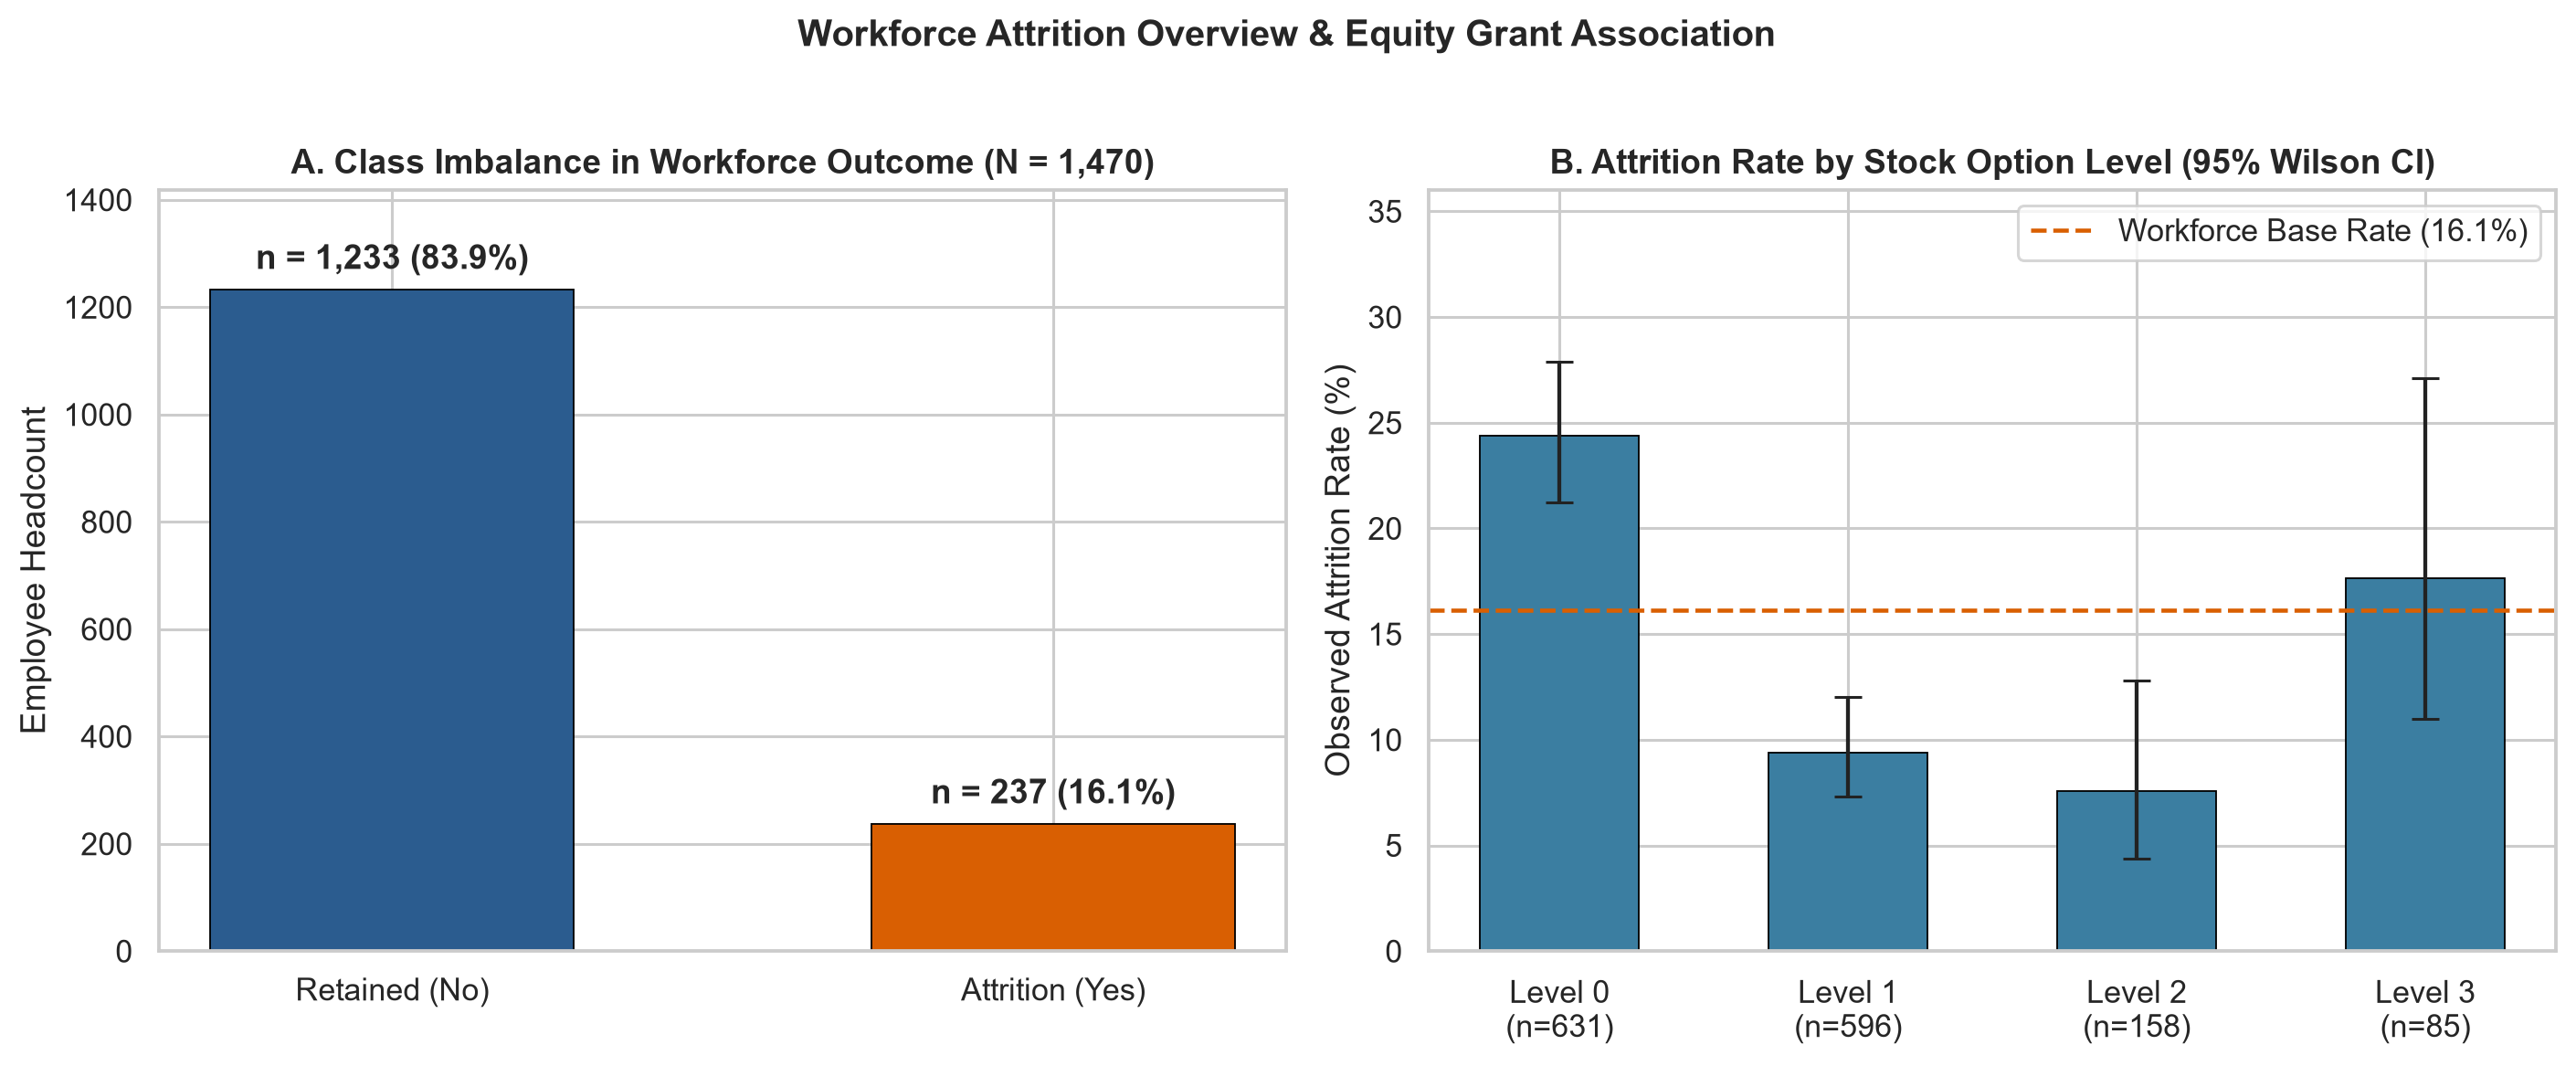

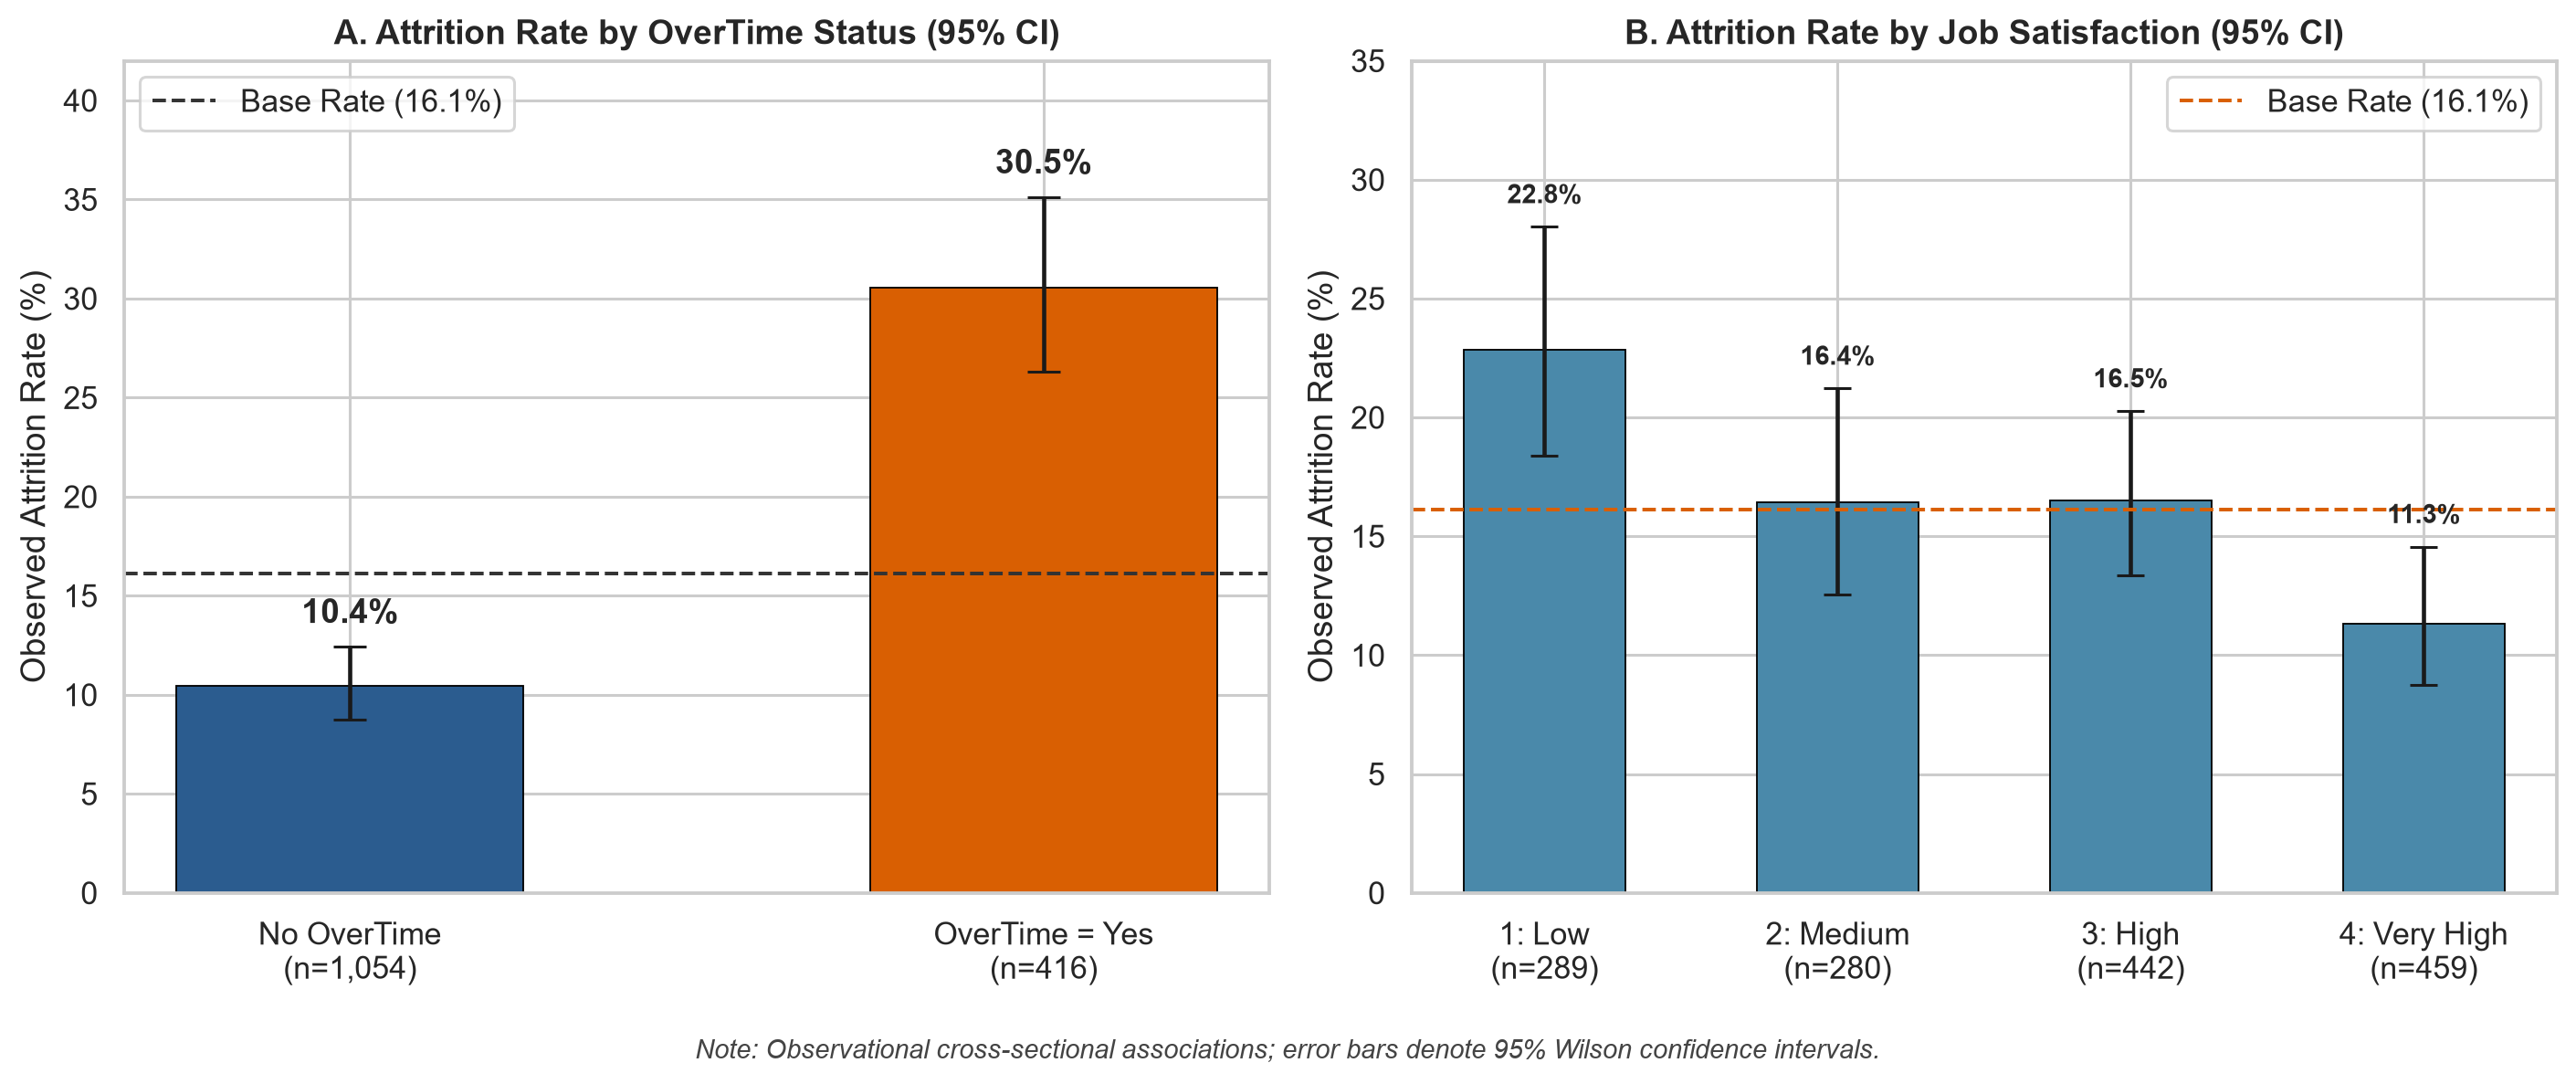

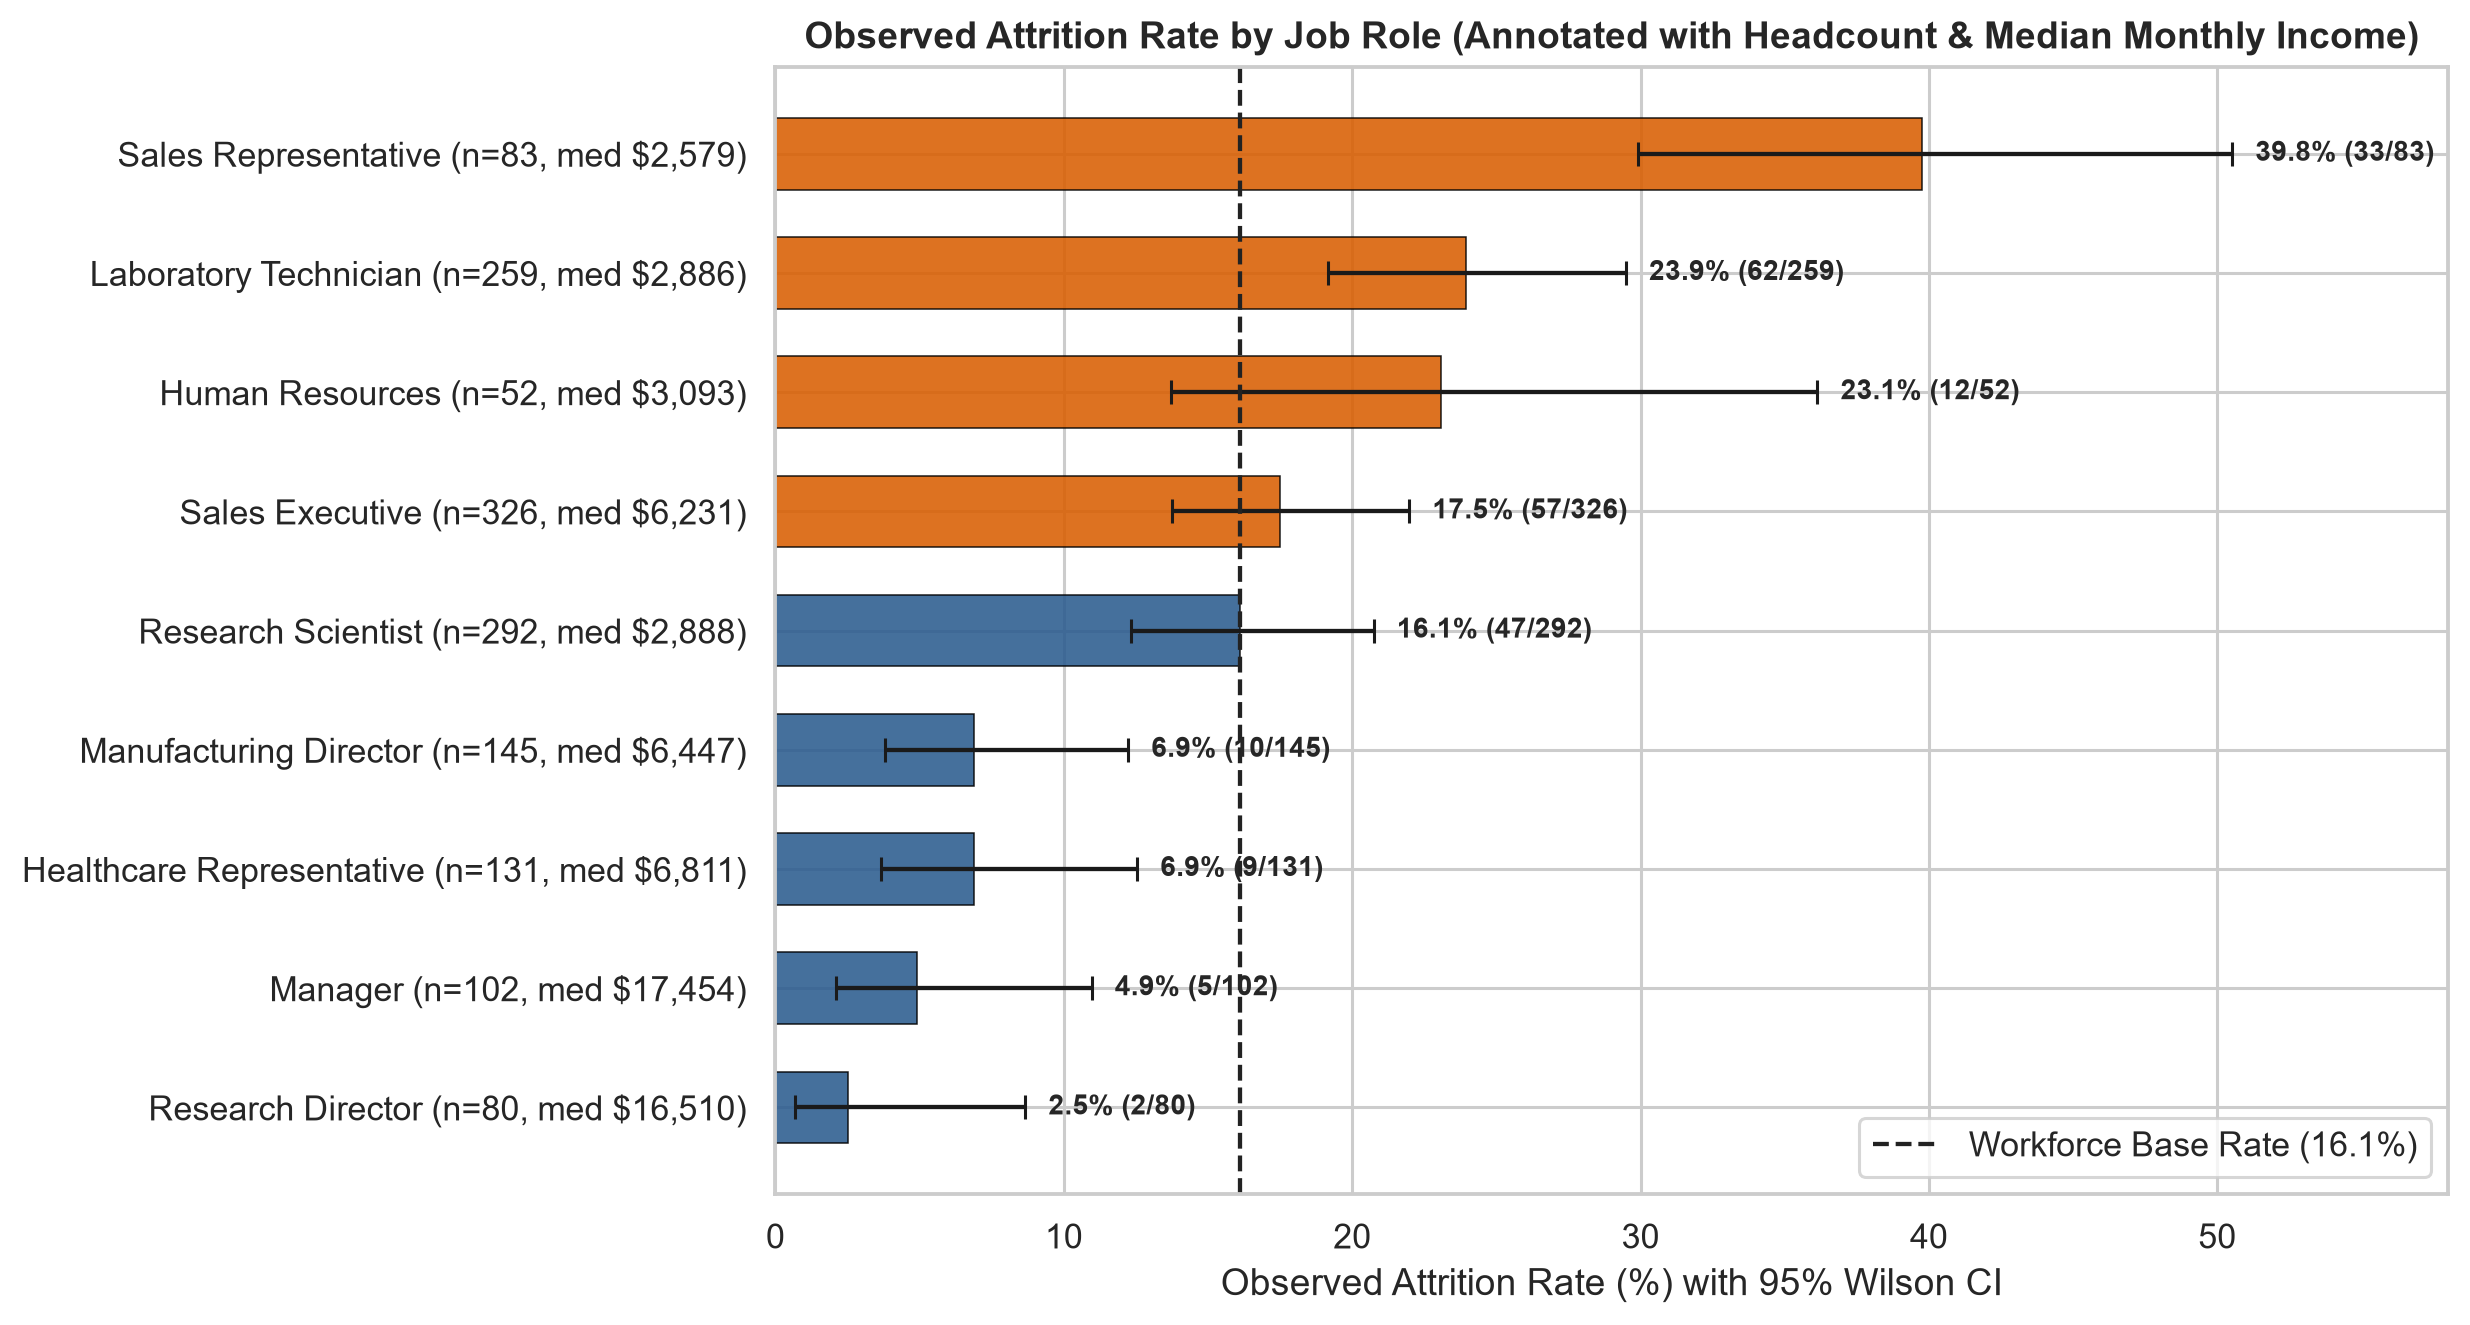

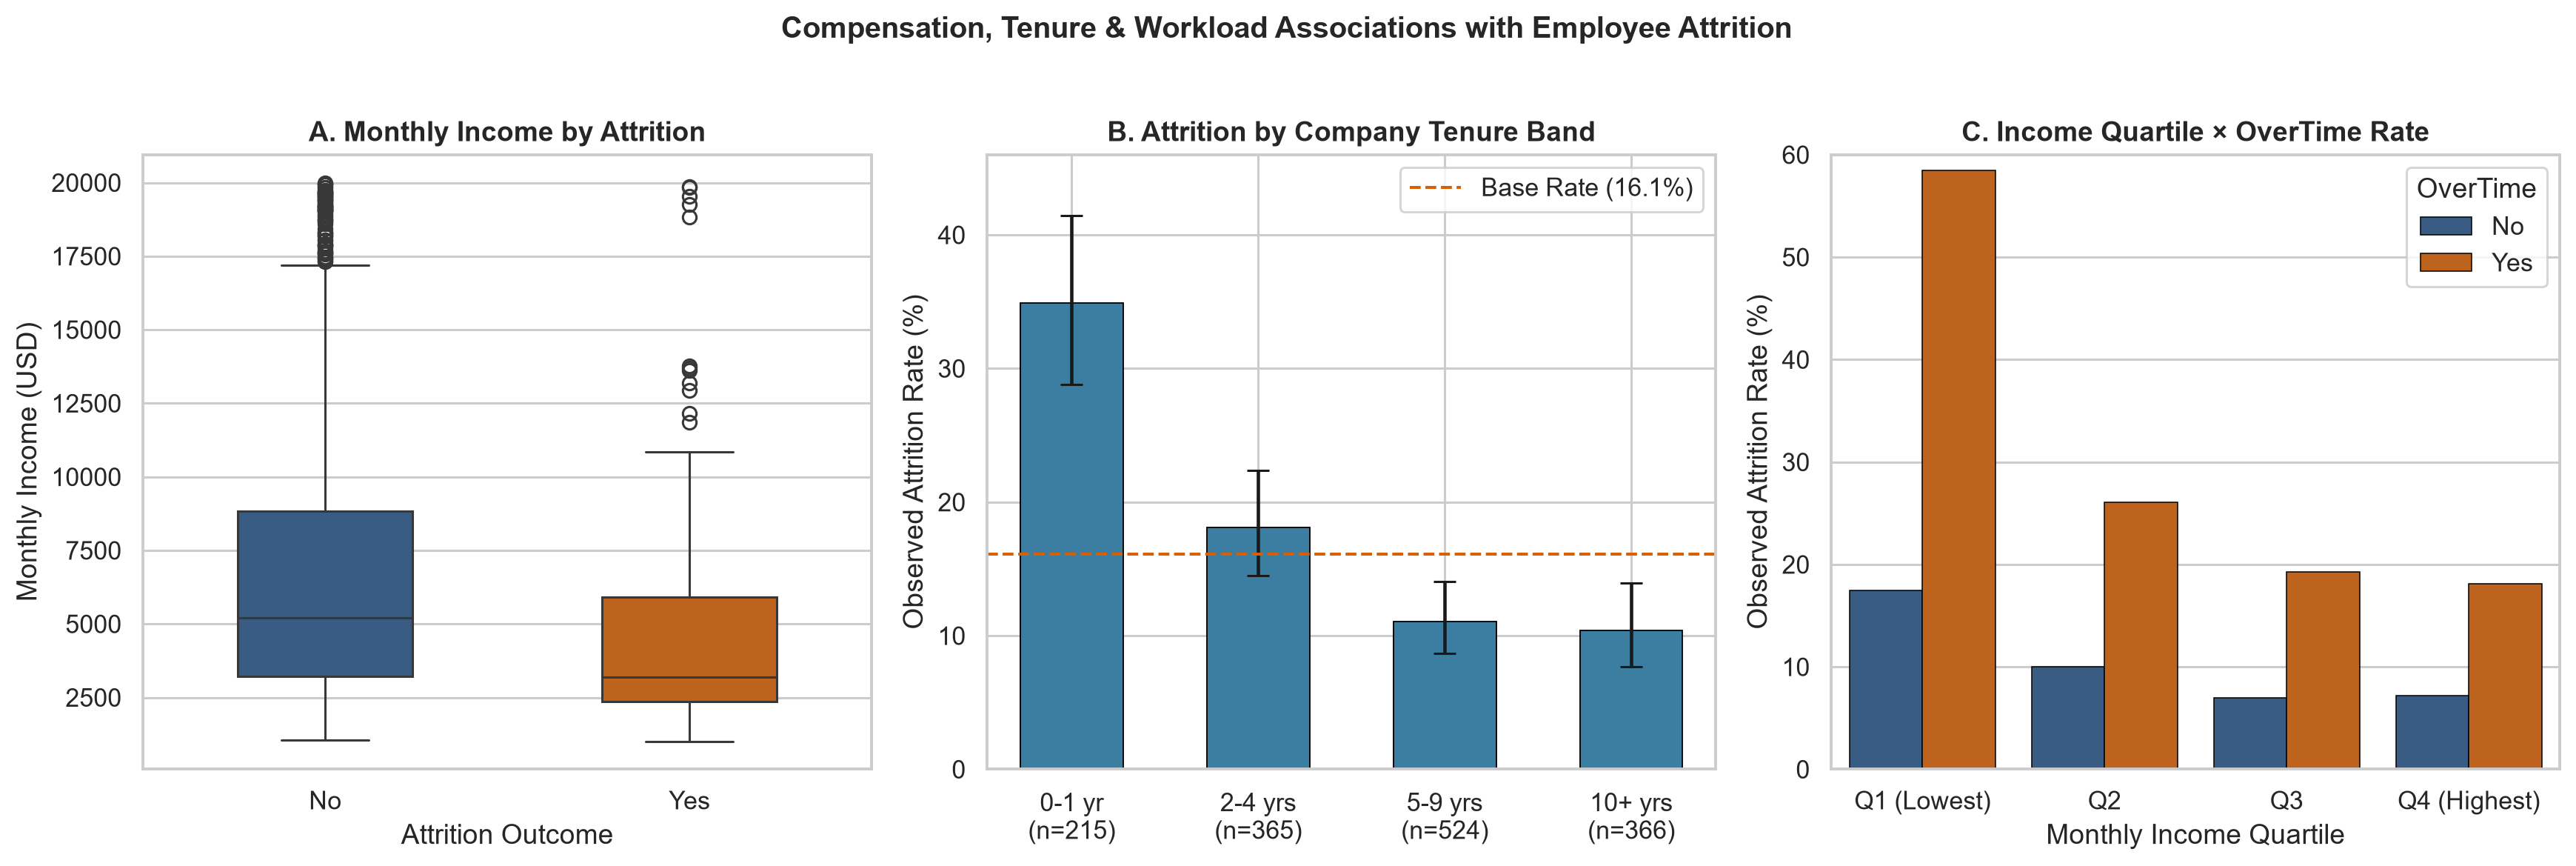

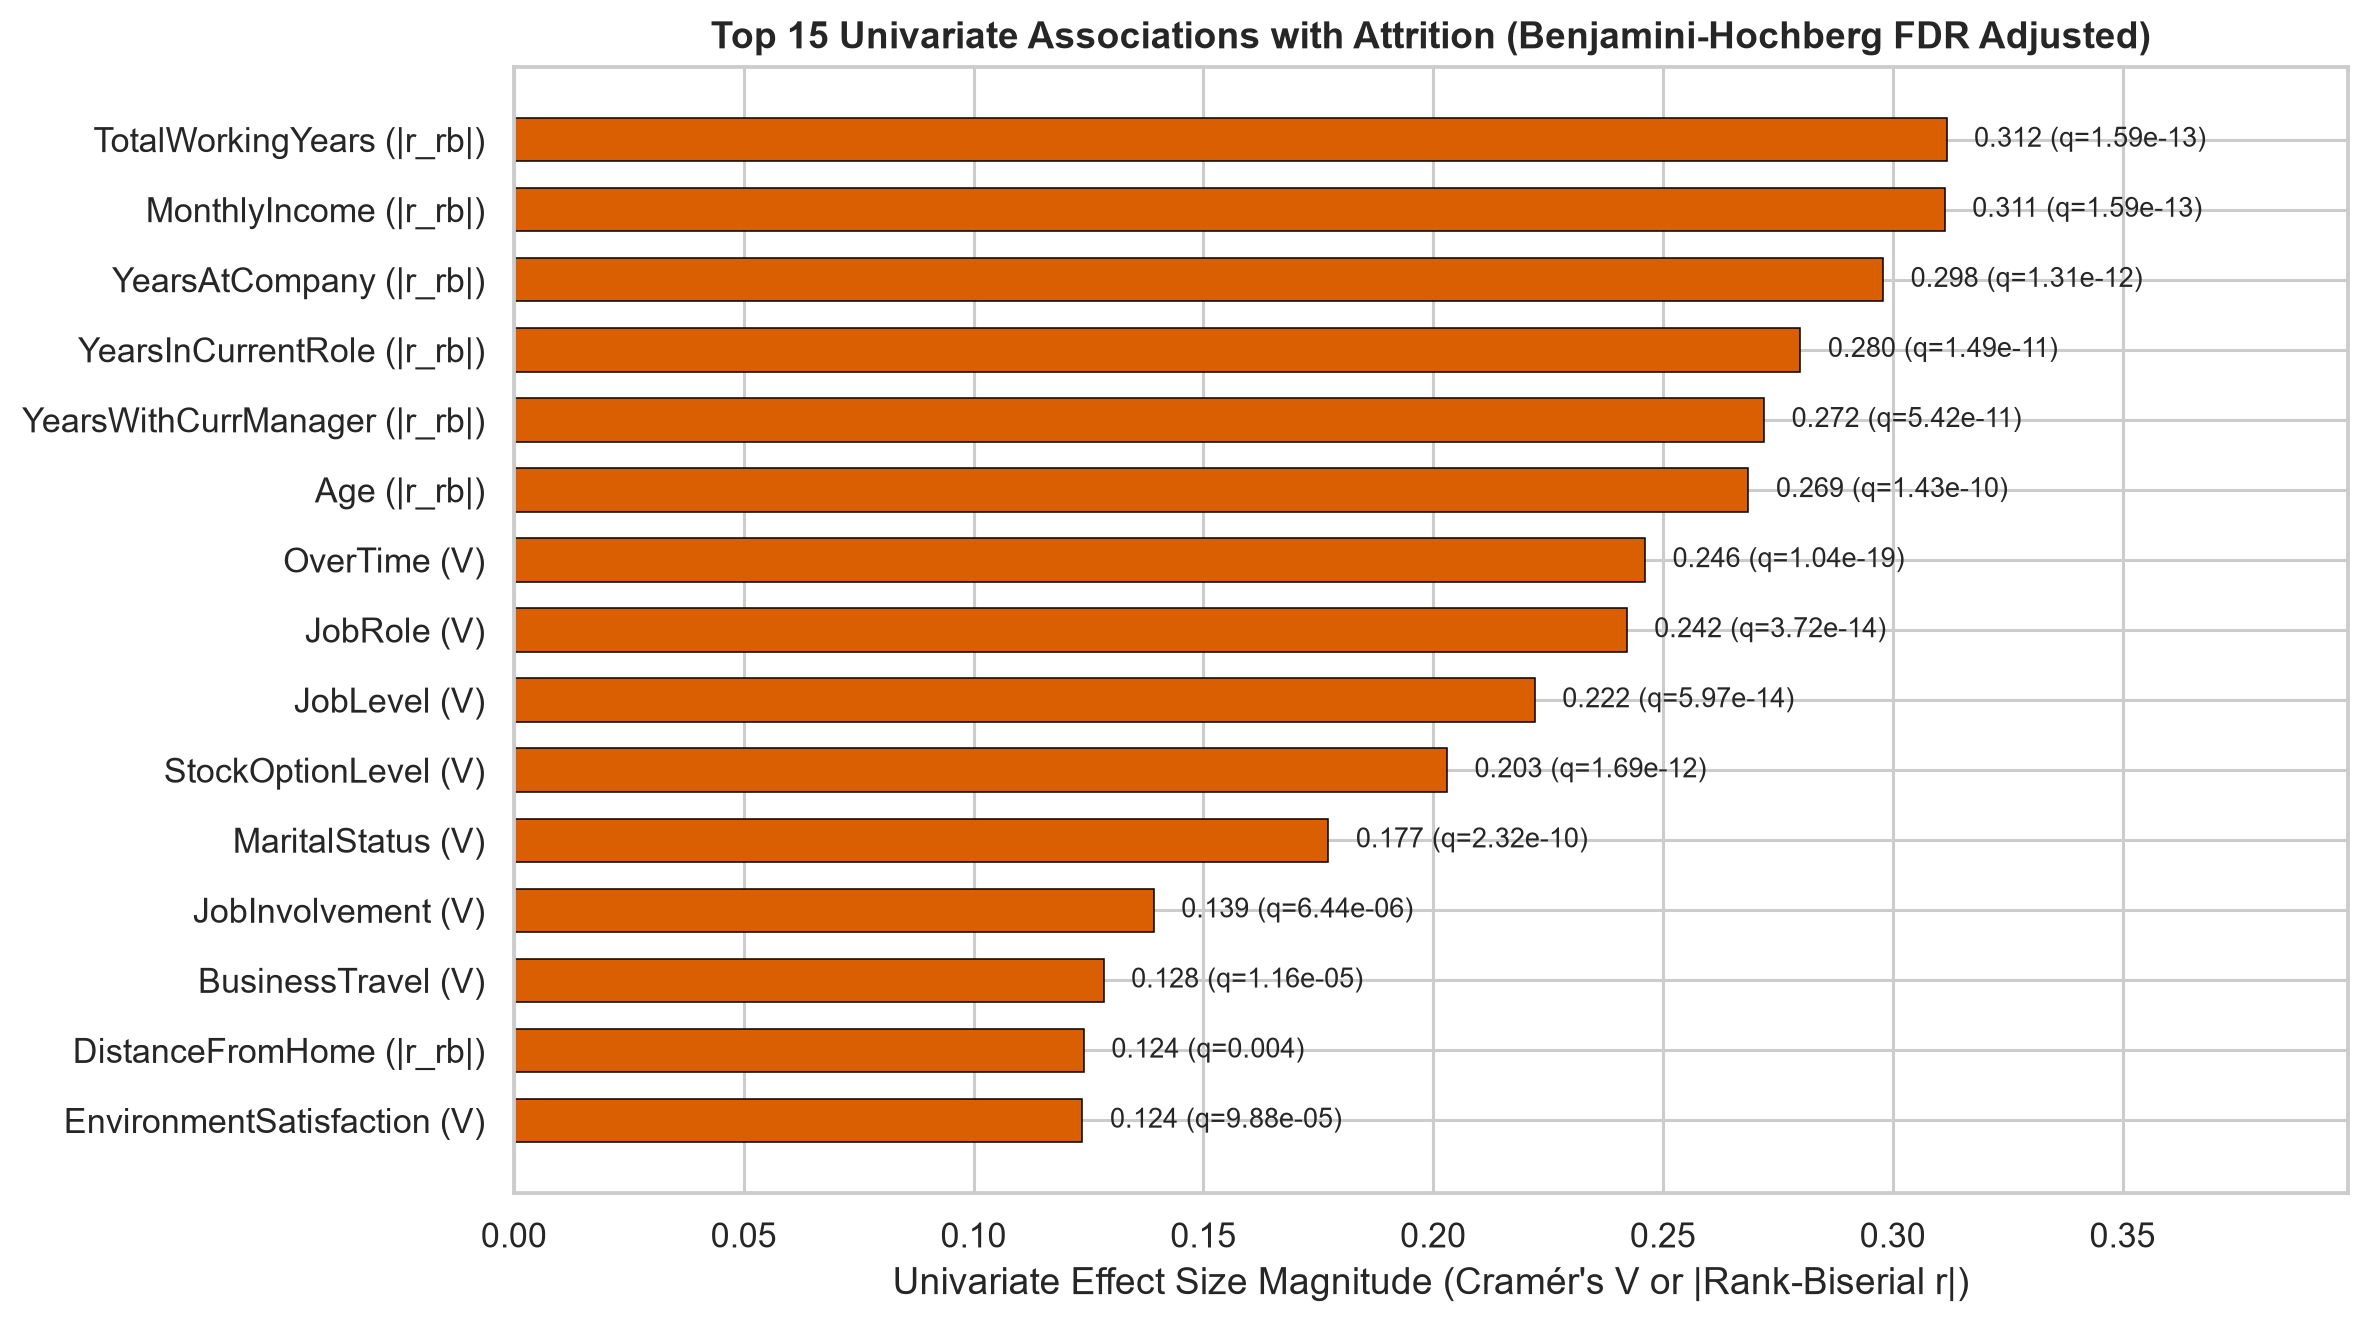

In [5]:
for fig_name in [
    "fig01_target_and_overview.png",
    "fig02_overtime_and_satisfaction.png",
    "fig03_job_role_attrition.png",
    "fig04_compensation_and_tenure.png",
    "fig05_statistical_effect_sizes.png",
]:
    display(Image(filename=str(cfg.figures_dir / fig_name), width=920))

---
## 3. Machine Learning Modeling, Threshold Optimization & Feature Importance

### Methodological Design
1. **Why L1-Regularized Logistic Regression instead of Ordinary Lasso?**
   Employee attrition is a binary outcome ($y \in \{0, 1\}$). Ordinary Lasso minimizes squared-error loss ($\|y - X\beta\|_2^2 + \lambda\|\beta\|_1$), producing unbounded predictions outside $[0, 1]$ and heteroskedastic variance. **L1-regularized logistic regression** maximizes the penalized binomial log-likelihood, inducing exact coefficient sparsity ($\ell_1$ feature selection) while preserving valid log-odds and bounded probabilities $P(y=1 \mid x) \in (0, 1)$.
2. **Leakage Prevention & Within-Fold Imbalance Handling**:
   - `EmployeeNumber`, `Attrition`, `AttritionFlag`, and constant columns are verified absent from `X`.
   - Stratified 80/20 split (`1,176` train / `294` held-out test; ~`16.1%` positive class in each).
   - `ImbPipeline` encapsulates `ColumnTransformer` (`SimpleImputer` + `StandardScaler` for numeric; `SimpleImputer` + `OneHotEncoder` for categorical) and class-imbalance handling (`SMOTE` or fold-computed class weights) strictly inside 5-fold `StratifiedKFold` on `X_train, y_train`.
3. **Validation Threshold Selection ($t^*$)**:
   - Out-of-fold validation probabilities on `X_train` are swept across $t \in [0.10, 0.89]$ to maximize validation $F_1$, balancing **False Positives** (unneeded retention outreach cost) against **False Negatives** (missed departing employees). The held-out test set is evaluated once using frozen $t^*$.

In [6]:
X, y = prepare_feature_matrix(clean_df, drop_sensitive=False)
print(f"Feature matrix shape: {X.shape} | Positive target rate: {y.mean():.4f}")

# Load persisted evaluation tables produced by the deterministic training pipeline
comp_df = pd.read_csv(cfg.metrics_dir / "model_comparison.csv")
perm_df = pd.read_csv(cfg.metrics_dir / "feature_importance.csv")
l1_coef_df = pd.read_csv(cfg.metrics_dir / "l1_logistic_coefficients.csv")

display(comp_df)

Feature matrix shape: (1470, 30) | Positive target rate: 0.1612


,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,oof_f1_at_val_threshold,selected_val_threshold,test_pr_auc,test_roc_auc,test_precision_default_050,test_recall_default_050,test_f1_default_050,test_precision_val_thr,test_recall_val_thr,test_f1_val_thr,test_tp,test_fp,test_tn,test_fn
0,XGBoost,0.639432,0.059663,0.829779,0.028842,0.566586,0.31,0.571469,0.809027,0.750000,0.382979,0.507042,0.409836,0.531915,0.462963,25,36,211,22
1,L1 Logistic Regression,0.623408,0.062005,0.828899,0.030863,0.593220,0.71,0.591420,0.809027,0.400000,0.680851,0.503937,0.567568,0.446809,0.500000,21,16,231,26
2,Baseline Logistic Regression,0.605412,0.081988,0.827153,0.028196,0.582633,0.74,0.556970,0.801878,0.348837,0.638298,0.451128,0.555556,0.425532,0.481928,20,16,231,27
3,Random Forest,0.594809,0.076327,0.816712,0.032682,0.534031,0.38,0.472207,0.799466,0.538462,0.297872,0.383562,0.428571,0.510638,0.466019,24,32,215,23


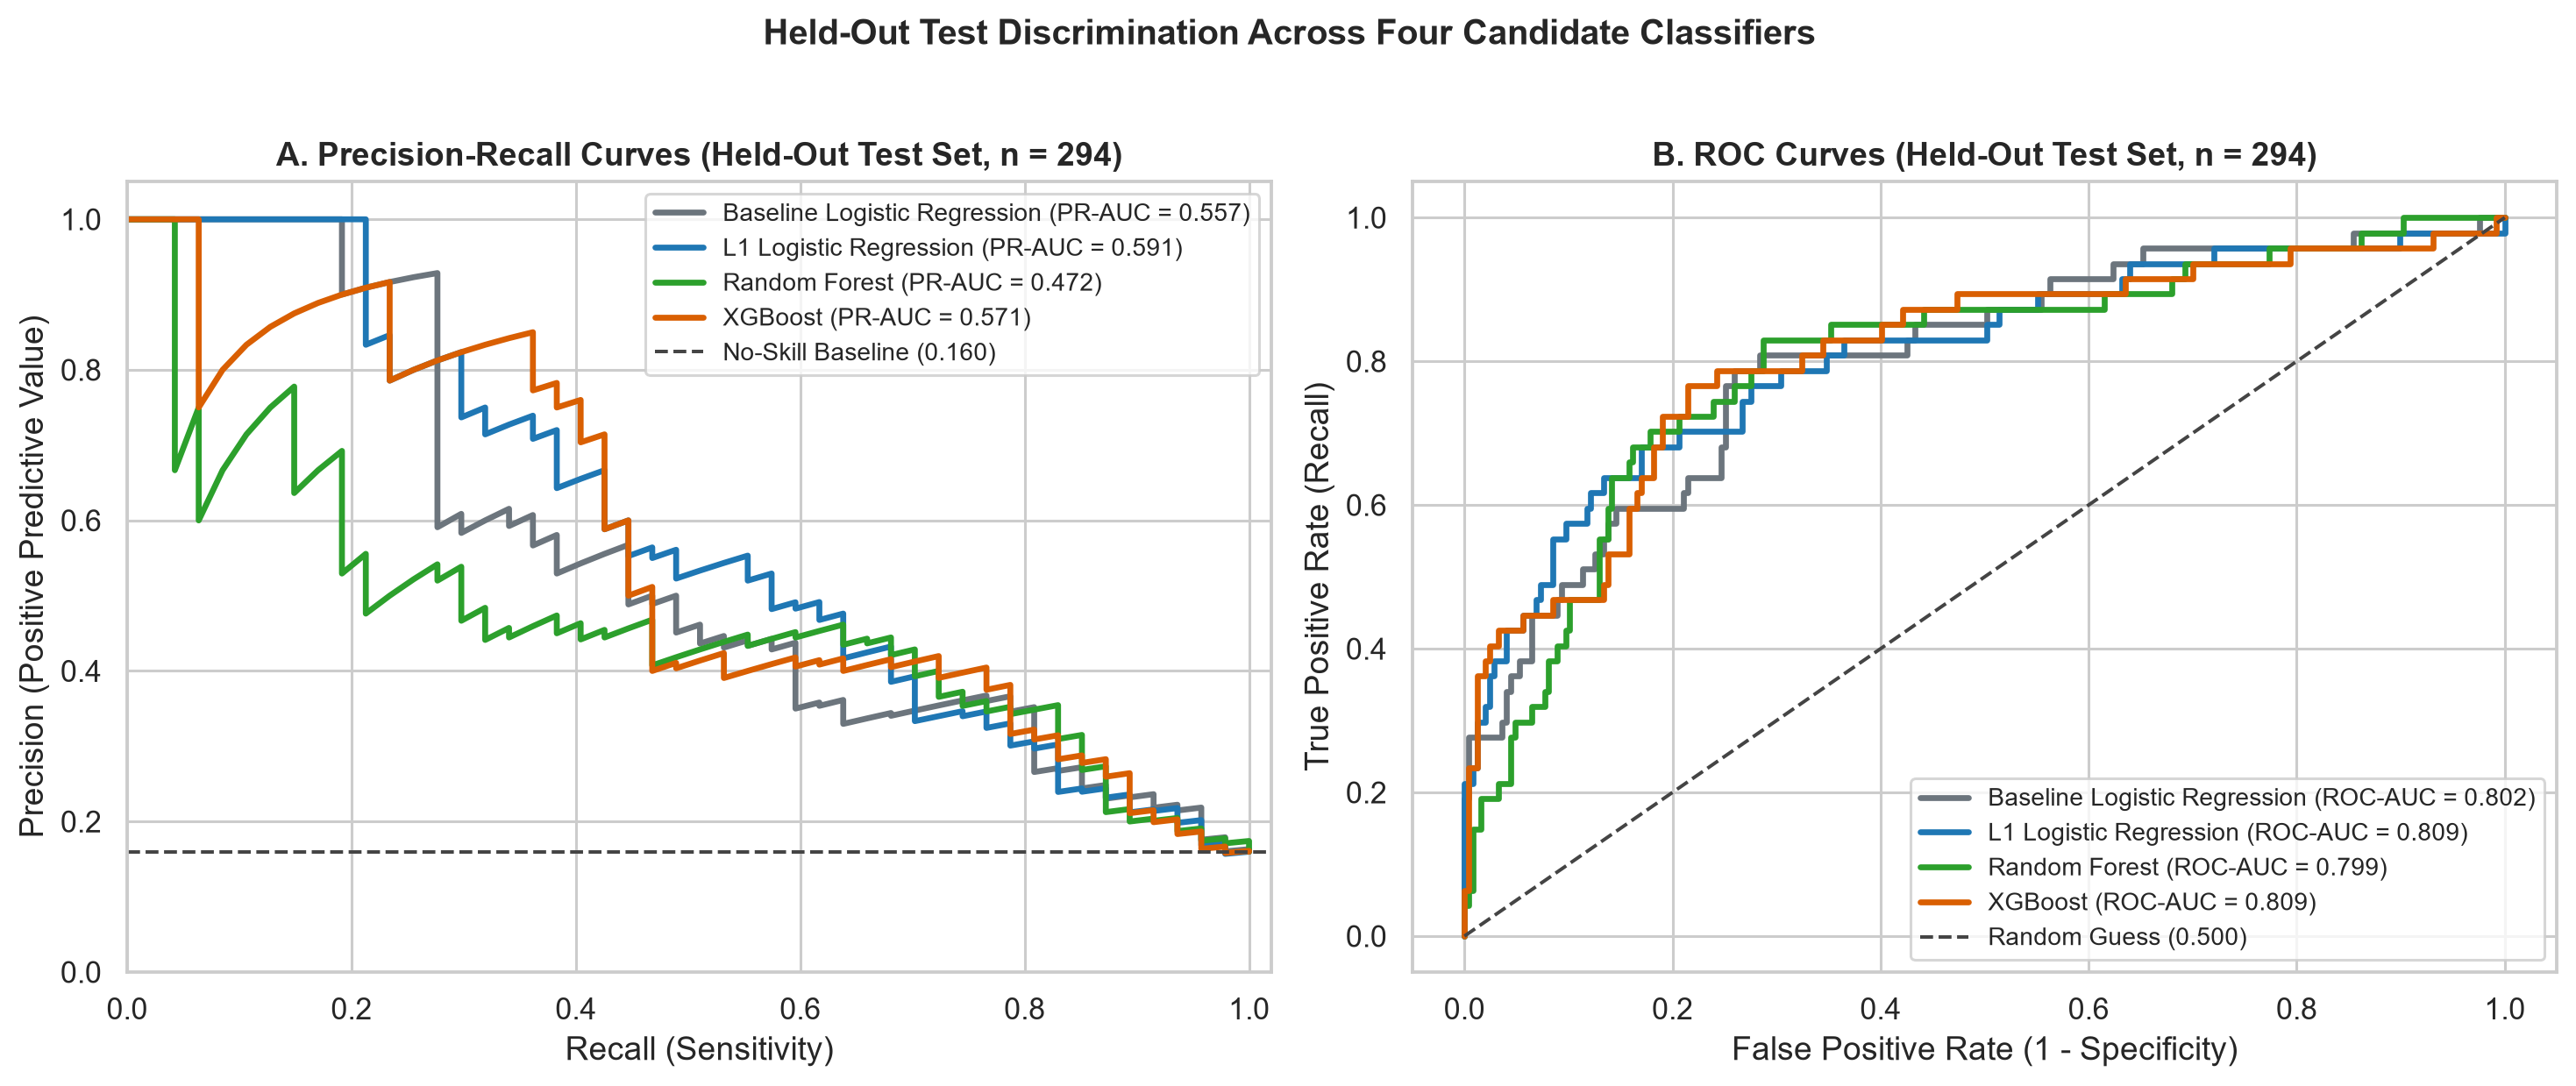

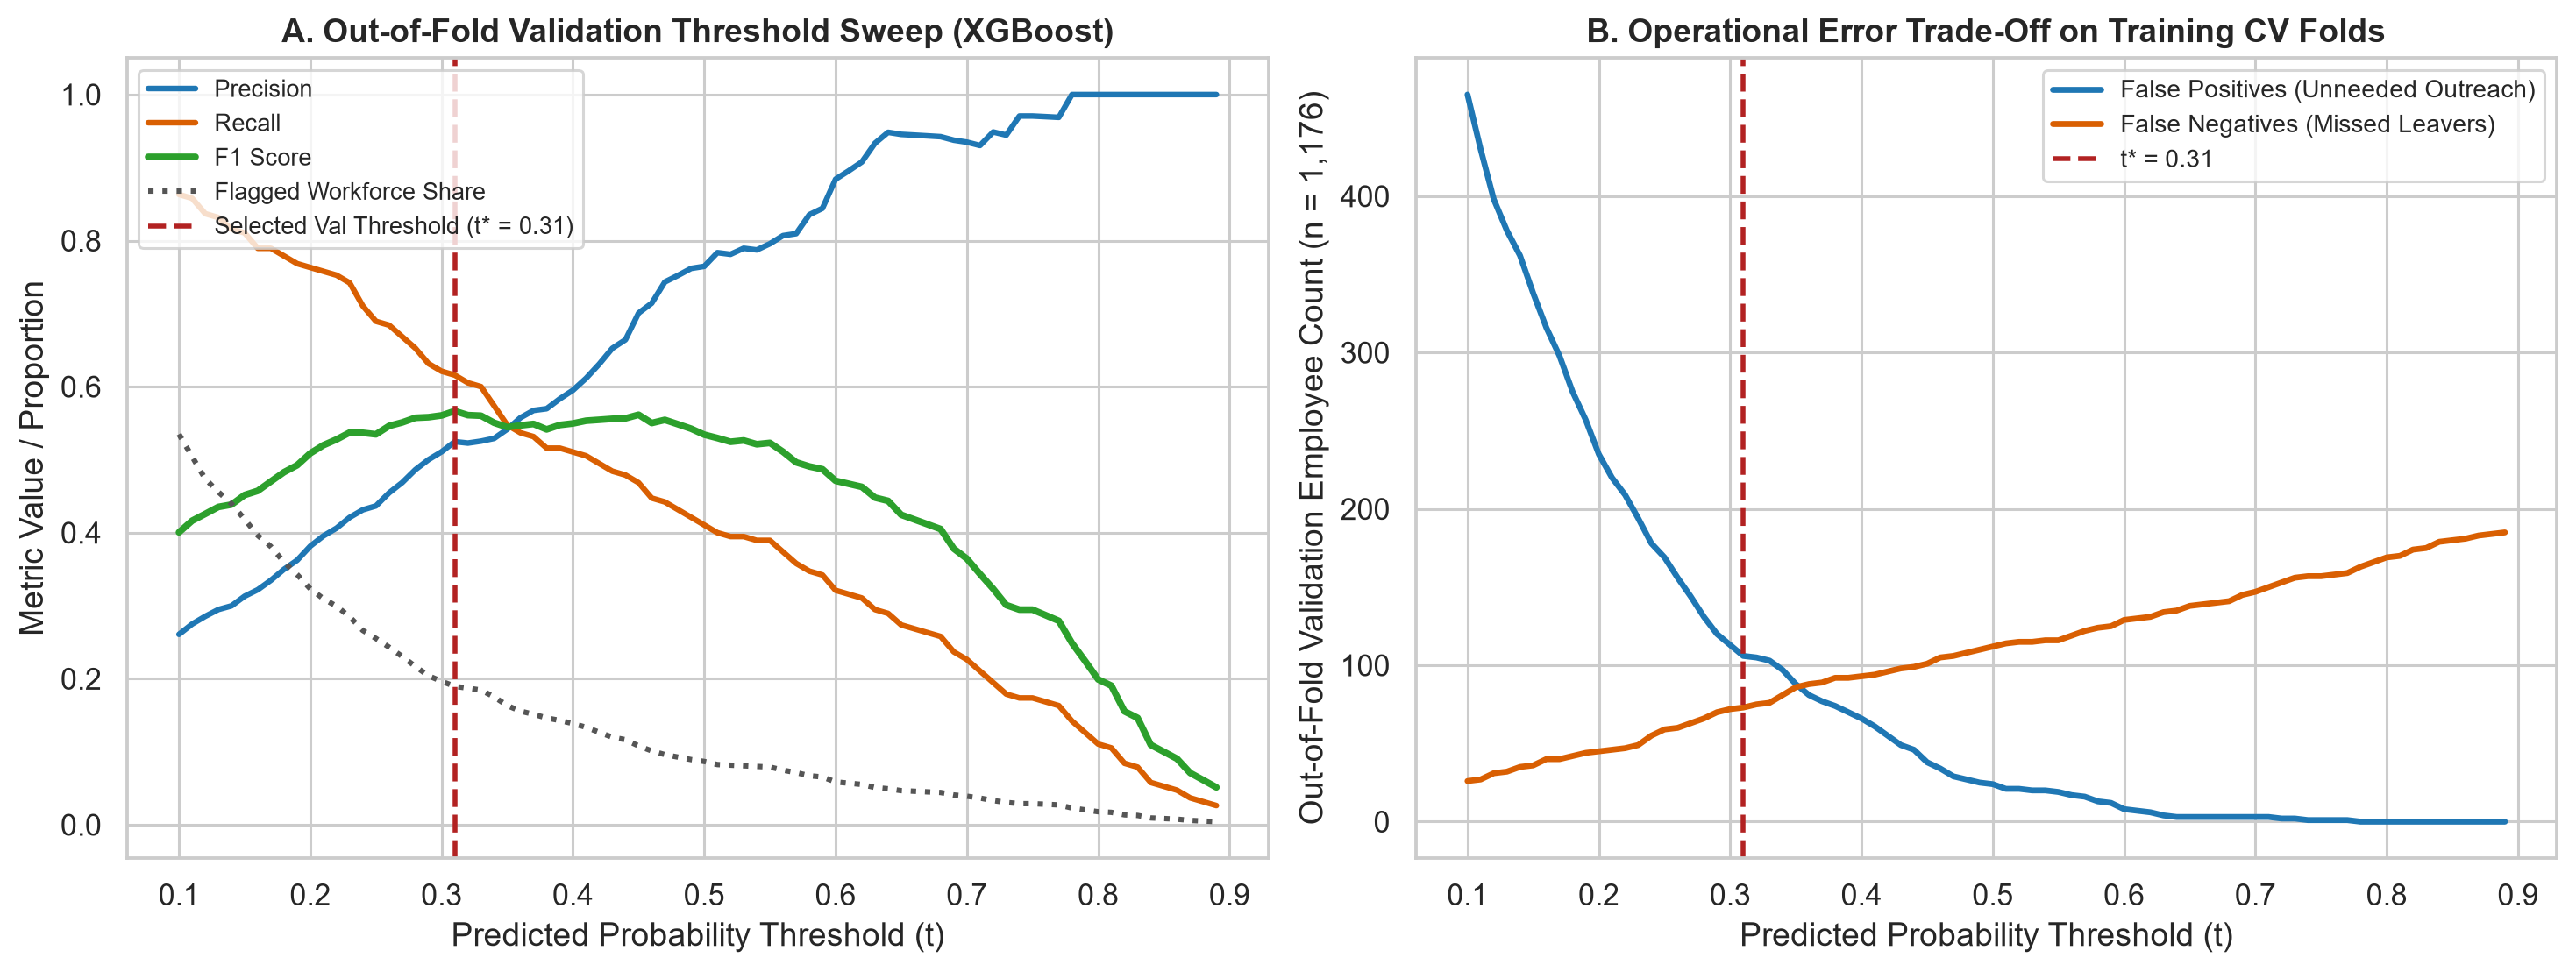

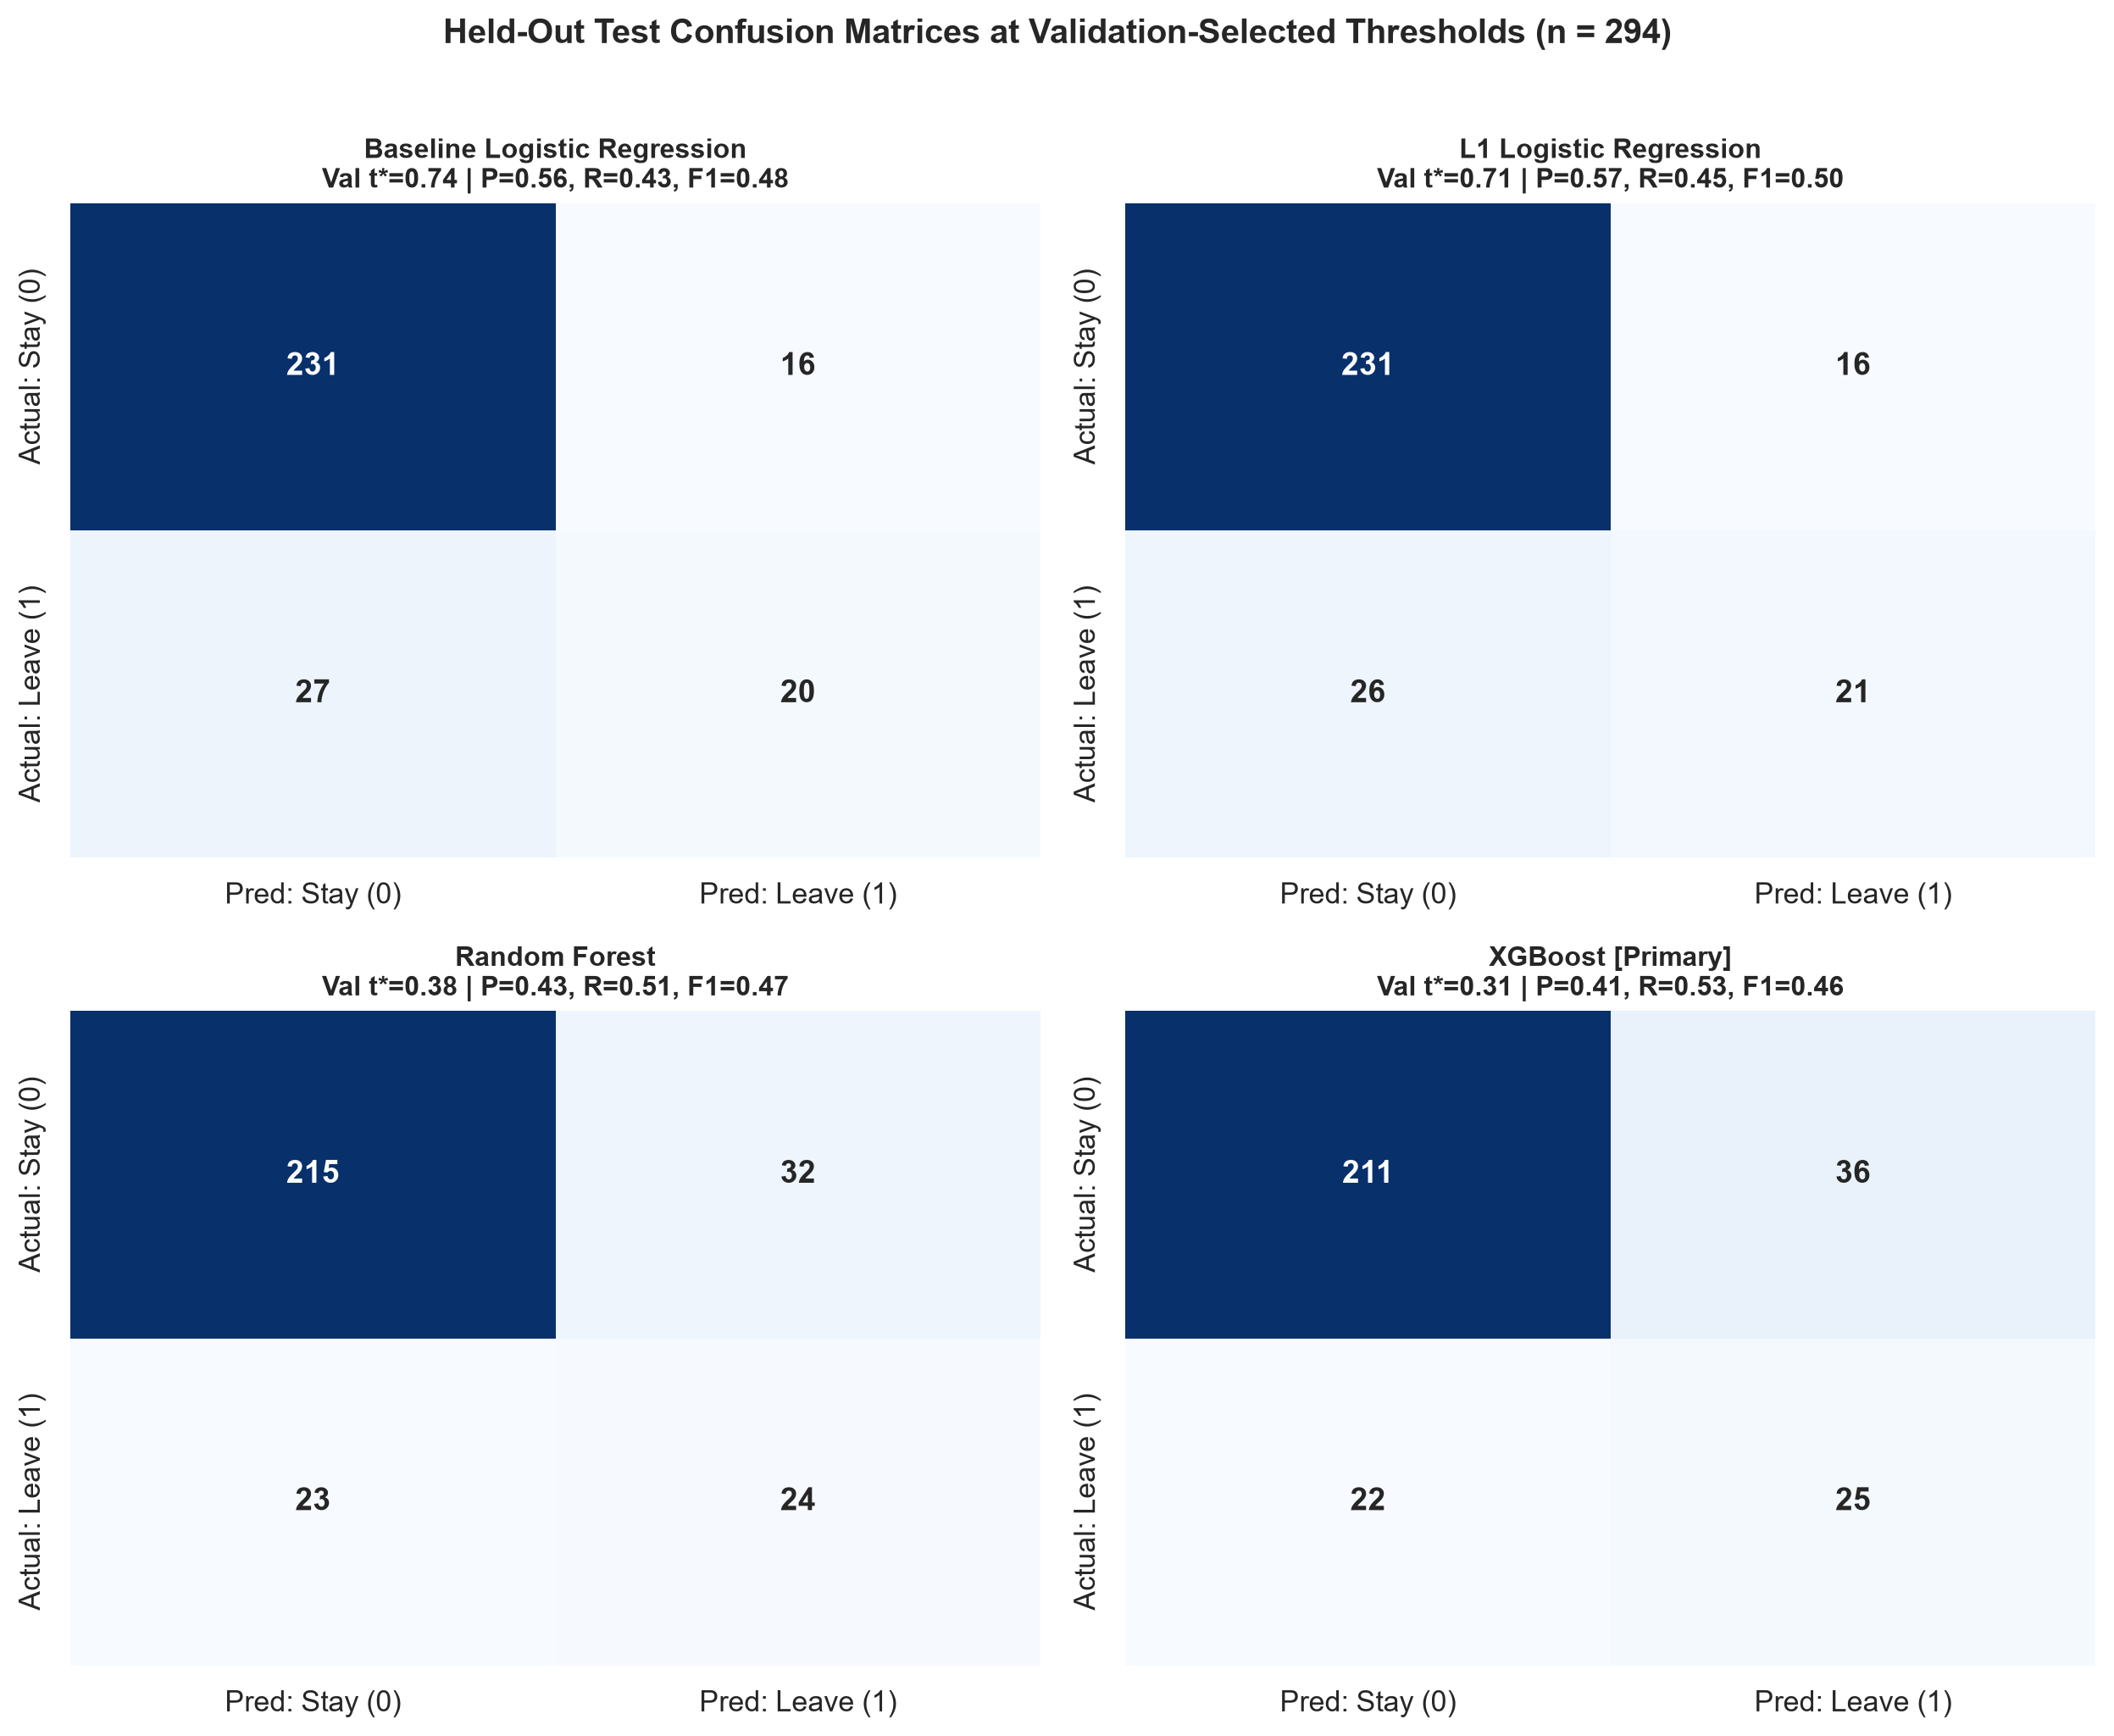

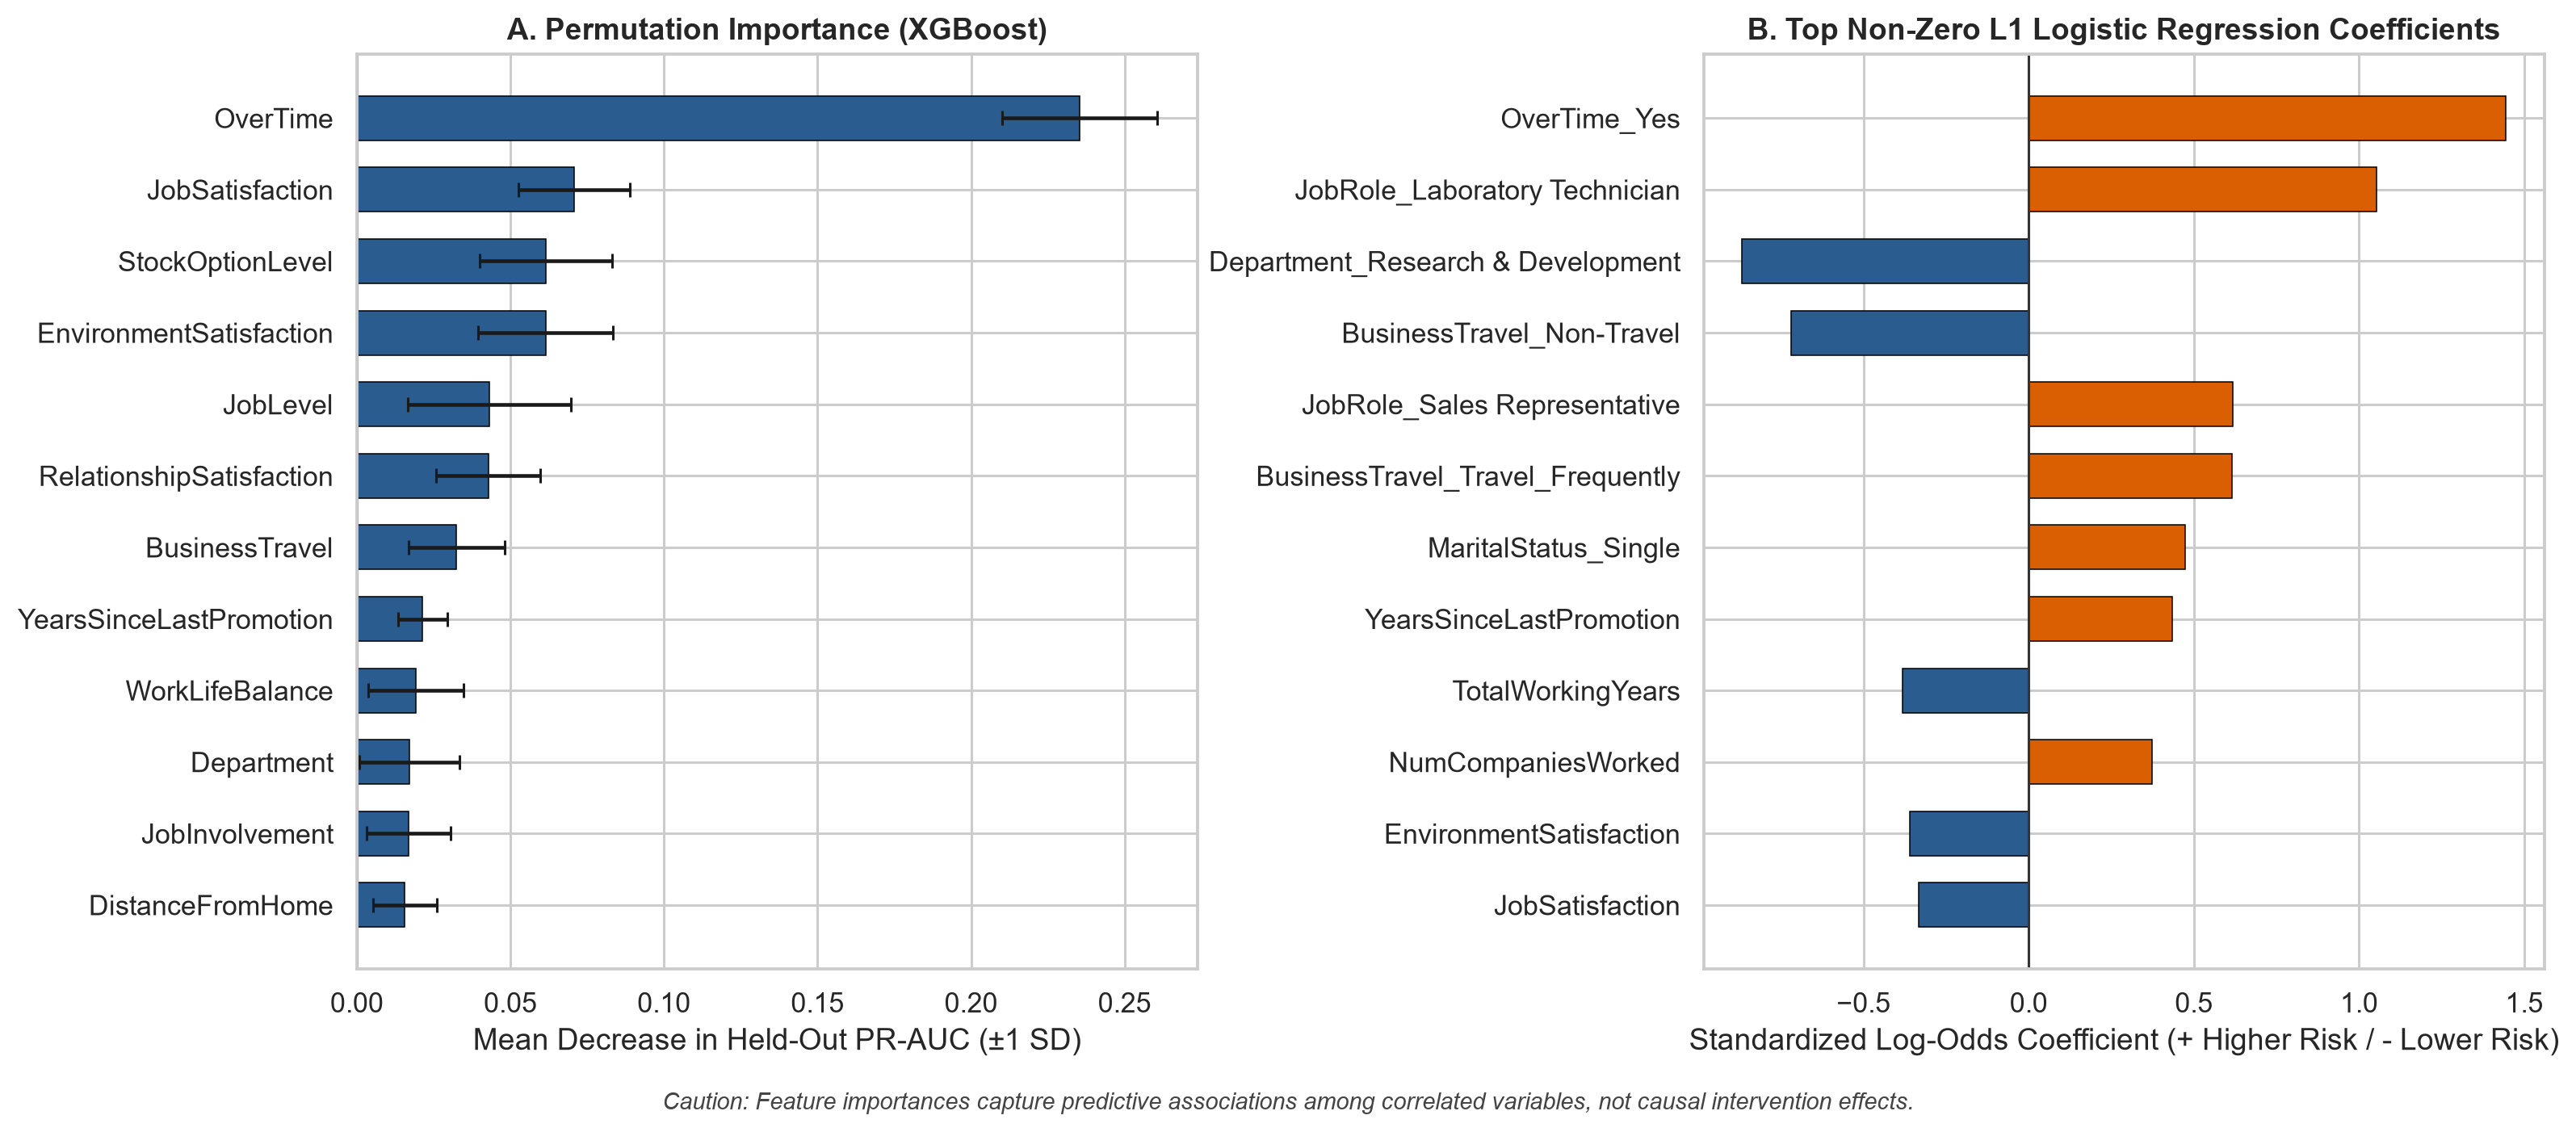

In [7]:
for fig_name in [
    "fig06_model_comparison_curves.png",
    "fig07_threshold_selection.png",
    "fig08_confusion_matrices.png",
    "fig09_feature_importance.png",
]:
    display(Image(filename=str(cfg.figures_dir / fig_name), width=920))

### Feature Importance Limitations: Empirical Collinearity in Action
Comparing **Permutation Importance** (XGBoost) against **L1 Logistic Regression Coefficients** reveals an important real-world lesson on feature importance interpretation:
- Both models rank **`OverTime`**, **`JobSatisfaction`**, **`EnvironmentSatisfaction`**, **`BusinessTravel`**, and **`YearsSinceLastPromotion`** among top predictive signals.
- Although `MonthlyIncome` had the second-strongest univariate association in Section 2 ($p = 2.95 \times 10^{-14}$), **L1 Logistic Regression sets `MonthlyIncome` and `JobLevel` to exact `0.0`**, allocating weight instead to strongly correlated proxies (`JobRole_Laboratory Technician`, `JobRole_Sales Representative`, `TotalWorkingYears`, `Age`). Similarly, permuting `MonthlyIncome` alone while holding `JobLevel` and `JobRole` fixed yields minimal marginal PR-AUC loss.
- Consequently, low feature importance in a regularized or tree model **never** implies a factor is irrelevant to retention—collinear compensation and seniority variables share predictive signal.

In [8]:
print("Top 10 Permutation Importances (Primary CV-Selected Model):")
display(perm_df.head(10))

print("\nZeroed-Out Features in L1 Logistic Regression (illustrating collinearity sparsity):")
display(l1_coef_df[~l1_coef_df["non_zero"]][["encoded_feature", "coefficient_log_odds"]])

Top 10 Permutation Importances (Primary CV-Selected Model):


,feature,pr_auc_drop_mean,pr_auc_drop_std
0,OverTime,0.235428,0.025180
1,JobSatisfaction,0.070700,0.018179
2,StockOptionLevel,0.061544,0.021486
3,EnvironmentSatisfaction,0.061432,0.022054
4,JobLevel,0.043211,0.026529
5,RelationshipSatisfaction,0.042815,0.016943
6,BusinessTravel,0.032458,0.015747
7,YearsSinceLastPromotion,0.021382,0.008040
8,WorkLifeBalance,0.019227,0.015472
9,Department,0.017080,0.016400



Zeroed-Out Features in L1 Logistic Regression (illustrating collinearity sparsity):


,encoded_feature,coefficient_log_odds
33,MonthlyIncome,0.0
34,JobLevel,0.0
35,Education,0.0
36,EducationField_Marketing,0.0
37,BusinessTravel_Travel_Rarely,0.0
38,Department_Human Resources,0.0
39,EducationField_Human Resources,0.0
40,Department_Sales,0.0
41,EducationField_Medical,0.0
42,JobRole_Manager,0.0


---
## 4. Business Impact & Retention Scenario Calculator

### Distinguishing Relative Reduction (%) vs. Percentage-Point Reduction (pp)
Conflating *relative* attrition reduction with *percentage-point* reduction is a common executive reporting error:
- At a **16.12% baseline attrition rate** in a **5,000-employee** organization (`806` expected annual departures):
  - A **10% relative reduction** lowers attrition by `1.61 percentage points` (`16.12% -> 14.51%`), retaining **~81 employees**.
  - A **10.0 percentage-point reduction** lowers attrition from `16.12%` to `6.12%`—a **62.0% relative drop**, retaining **500 employees** (>6x larger!).

### Why Predictive Accuracy Alone Does Not Establish Cost Savings
High PR-AUC or ROC-AUC tells HR *who* is at elevated status-quo risk of leaving ($P(Y=1 \mid X)$), **not** whether an intervention will change their decision ($P(Y(1)=0 \mid Y(0)=1, X)$). As shown in the `Zero-Efficacy Null Intervention (eta=0%)` row below, deploying an ineffective intervention produces negative net savings (`-$1.56M`) regardless of model accuracy. A prospective **randomized pilot** is required to measure causal intervention effectiveness ($\eta$) before scaling.

,scenario_name,workforce_size,baseline_attrition_rate_pct,assumed_intervention_effectiveness_pct,model_recall,model_fpr,replacement_cost_per_departure,intervention_cost_per_flagged,baseline_departures,flagged_employees,true_leavers_contacted,false_positives_contacted,prevented_departures,post_attrition_rate_pct,achieved_relative_reduction_pct,achieved_percentage_point_reduction_pp,gross_replacement_savings,total_intervention_cost,net_cost_savings,roi_pct,breakeven_effectiveness_pct
0,Conservative ML-Targeted (eta=10%),5000,16.122,10.0,0.5319,0.1457,45000.0,1500.0,806.12,1040.04,428.79,611.25,42.88,15.265,5.319,0.858,1929542.55,1560061.5,369481.05,23.68,8.0851
1,Moderate ML-Targeted (eta=15%),5000,16.122,15.0,0.5319,0.1457,45000.0,1500.0,806.12,1040.04,428.79,611.25,64.32,14.836,7.979,1.286,2894313.83,1560061.5,1334252.33,85.53,8.0851
2,Optimistic ML-Targeted (eta=25%),5000,16.122,25.0,0.5319,0.1457,45000.0,1500.0,806.12,1040.04,428.79,611.25,107.20,13.978,13.298,2.144,4823856.38,1560061.5,3263794.88,209.21,8.0851
3,Untargeted Blanket Program (eta=15%),5000,16.122,15.0,1.0000,1.0000,45000.0,1500.0,806.12,5000.00,806.12,4193.88,120.92,13.704,15.000,2.418,5441310.00,7500000.0,-2058690.00,-27.45,20.6752
4,Zero-Efficacy Null Intervention (eta=0%),5000,16.122,0.0,0.5319,0.1457,45000.0,1500.0,806.12,1040.04,428.79,611.25,0.00,16.122,0.000,0.000,0.00,1560061.5,-1560061.50,-100.00,8.0851



Explicit Comparison — 10% Relative Reduction vs. 2.0 Percentage-Point Reduction:
10% Relative: AttritionReductionComparison(baseline_rate_pct=16.1224, post_intervention_rate_pct=14.5102, relative_reduction_pct=10.0, percentage_point_reduction_pp=1.6122, departures_baseline=806.12, departures_prevented=80.61, departures_post=725.51)
2.0 pp Drop : AttritionReductionComparison(baseline_rate_pct=16.1224, post_intervention_rate_pct=14.1224, relative_reduction_pct=12.4051, percentage_point_reduction_pp=2.0, departures_baseline=806.12, departures_prevented=100.0, departures_post=706.12)


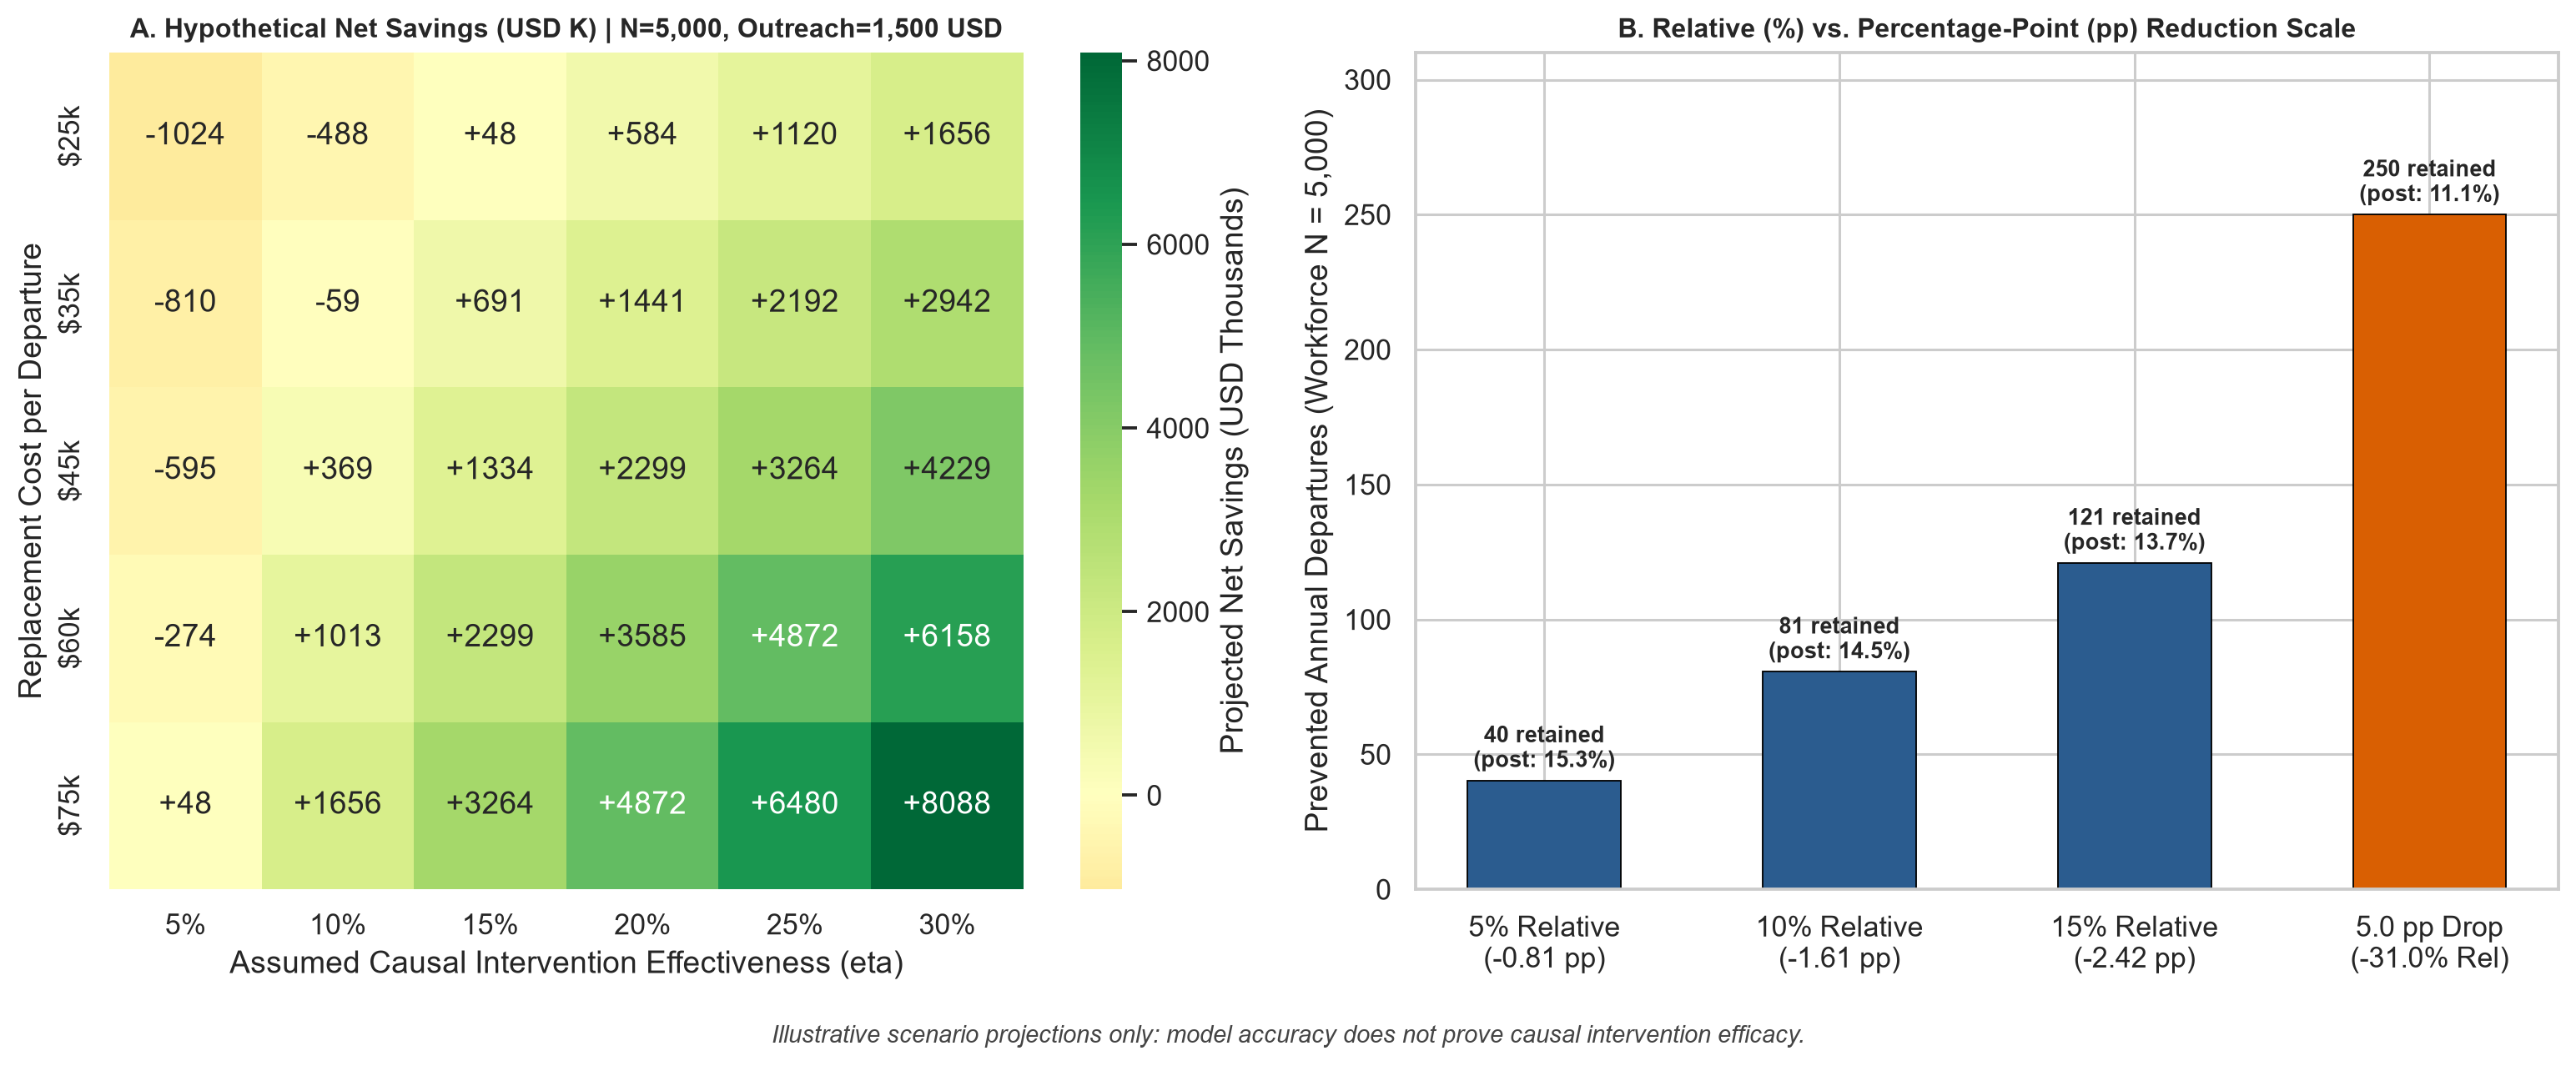

In [9]:
scen_df = pd.read_csv(cfg.metrics_dir / "business_scenarios.csv")
display(scen_df)

print("\nExplicit Comparison — 10% Relative Reduction vs. 2.0 Percentage-Point Reduction:")
print("10% Relative:", convert_attrition_reduction(
    workforce_size=5000, baseline_attrition_rate=0.161224, reduction_mode="relative", reduction_amount=0.10
))
print("2.0 pp Drop :", convert_attrition_reduction(
    workforce_size=5000, baseline_attrition_rate=0.161224, reduction_mode="percentage_point", reduction_amount=2.0
))

display(Image(filename=str(cfg.figures_dir / "fig10_business_scenario_sensitivity.png"), width=920))

---
## 5. Responsible Use, Subgroup Audit & Deployment Governance

1. **Dataset Provenance & Deployment Limitations**:
   - The IBM HR dataset is a **fictional benchmark created by IBM data scientists** for Watson Analytics—not empirical enterprise HRIS logs. It is a single cross-sectional snapshot ($N=1,470$) without hire/exit dates (precluding survival analysis for right-censored tenure) and does not separate *voluntary resignations* from *involuntary terminations*.
2. **Identifier & Sensitive Attribute Governance**:
   - `EmployeeNumber` is strictly excluded from model inputs.
   - Auditing subgroup metrics on the held-out test set below uncovers an actionable disparity: although workers aged `40+` (ADEA-protected) have nearly the same test-set base attrition rate (`15.8%`) as workers `Under 40` (`16.1%`), the model flags `Under 40` workers at nearly twice the rate (`24.9%` vs. `12.9%`) and achieves much lower recall on `40+` employees (`31.3%` vs. `64.5%`). Removing `Age`, `Gender`, and `MaritalStatus` reduces held-out PR-AUC only slightly (`0.576 -> 0.563` in our L1 ablation), demonstrating that proxy variables (`TotalWorkingYears`, `StockOptionLevel`) carry most of the signal and that **ongoing subgroup auditing is mandatory even if demographic columns are dropped**.
3. **Privacy, Human Oversight & Voluntary Positioning**:
   - Risk scores must never inform punitive actions (layoffs, firing, promotion denial, or pay suppression). Predictions should serve strictly as confidential decision-support signals for trained HR partners to offer **voluntary, supportive retention resources** (workload balancing, internal mobility, stay interviews, and compensation equity reviews).

,dimension,subgroup,n_test,attrition_count,base_attrition_rate,flagged_selection_rate,precision,recall_tpr,false_positive_rate,f1,pr_auc
0,Gender,Female,116,16,0.1379,0.2155,0.4000,0.6250,0.1500,0.4878,0.5235
1,Gender,Male,178,31,0.1742,0.2022,0.4167,0.4839,0.1429,0.4478,0.6212
2,AgeGroup,Under 30,68,17,0.2500,0.3824,0.4231,0.6471,0.2941,0.5116,0.6113
3,AgeGroup,30-44,173,21,0.1214,0.1734,0.4000,0.5714,0.1184,0.4706,0.6315
4,AgeGroup,45+,53,9,0.1698,0.0943,0.4000,0.2222,0.0682,0.2857,0.5222
5,AgeADEA40Plus,40+ (ADEA Protected),101,16,0.1584,0.1287,0.3846,0.3125,0.0941,0.3448,0.5428
6,AgeADEA40Plus,Under 40,193,31,0.1606,0.2487,0.4167,0.6452,0.1728,0.5063,0.6067
7,MaritalStatus,Divorced,64,4,0.0625,0.1250,0.3750,0.7500,0.0833,0.5000,0.3811
8,MaritalStatus,Married,133,18,0.1353,0.1504,0.3500,0.3889,0.1130,0.3684,0.5088
9,MaritalStatus,Single,97,25,0.2577,0.3402,0.4545,0.6000,0.2500,0.5172,0.6600



Sensitive-Attribute Ablation Check (L1 Logistic Regression):
{
  "with_demographics": {
    "feature_count": 30,
    "cv_pr_auc_mean": 0.6123,
    "test_pr_auc": 0.5762,
    "test_roc_auc": 0.8051
  },
  "without_age_gender_marital": {
    "feature_count": 27,
    "cv_pr_auc_mean": 0.6019,
    "test_pr_auc": 0.5632,
    "test_roc_auc": 0.7822
  }
}


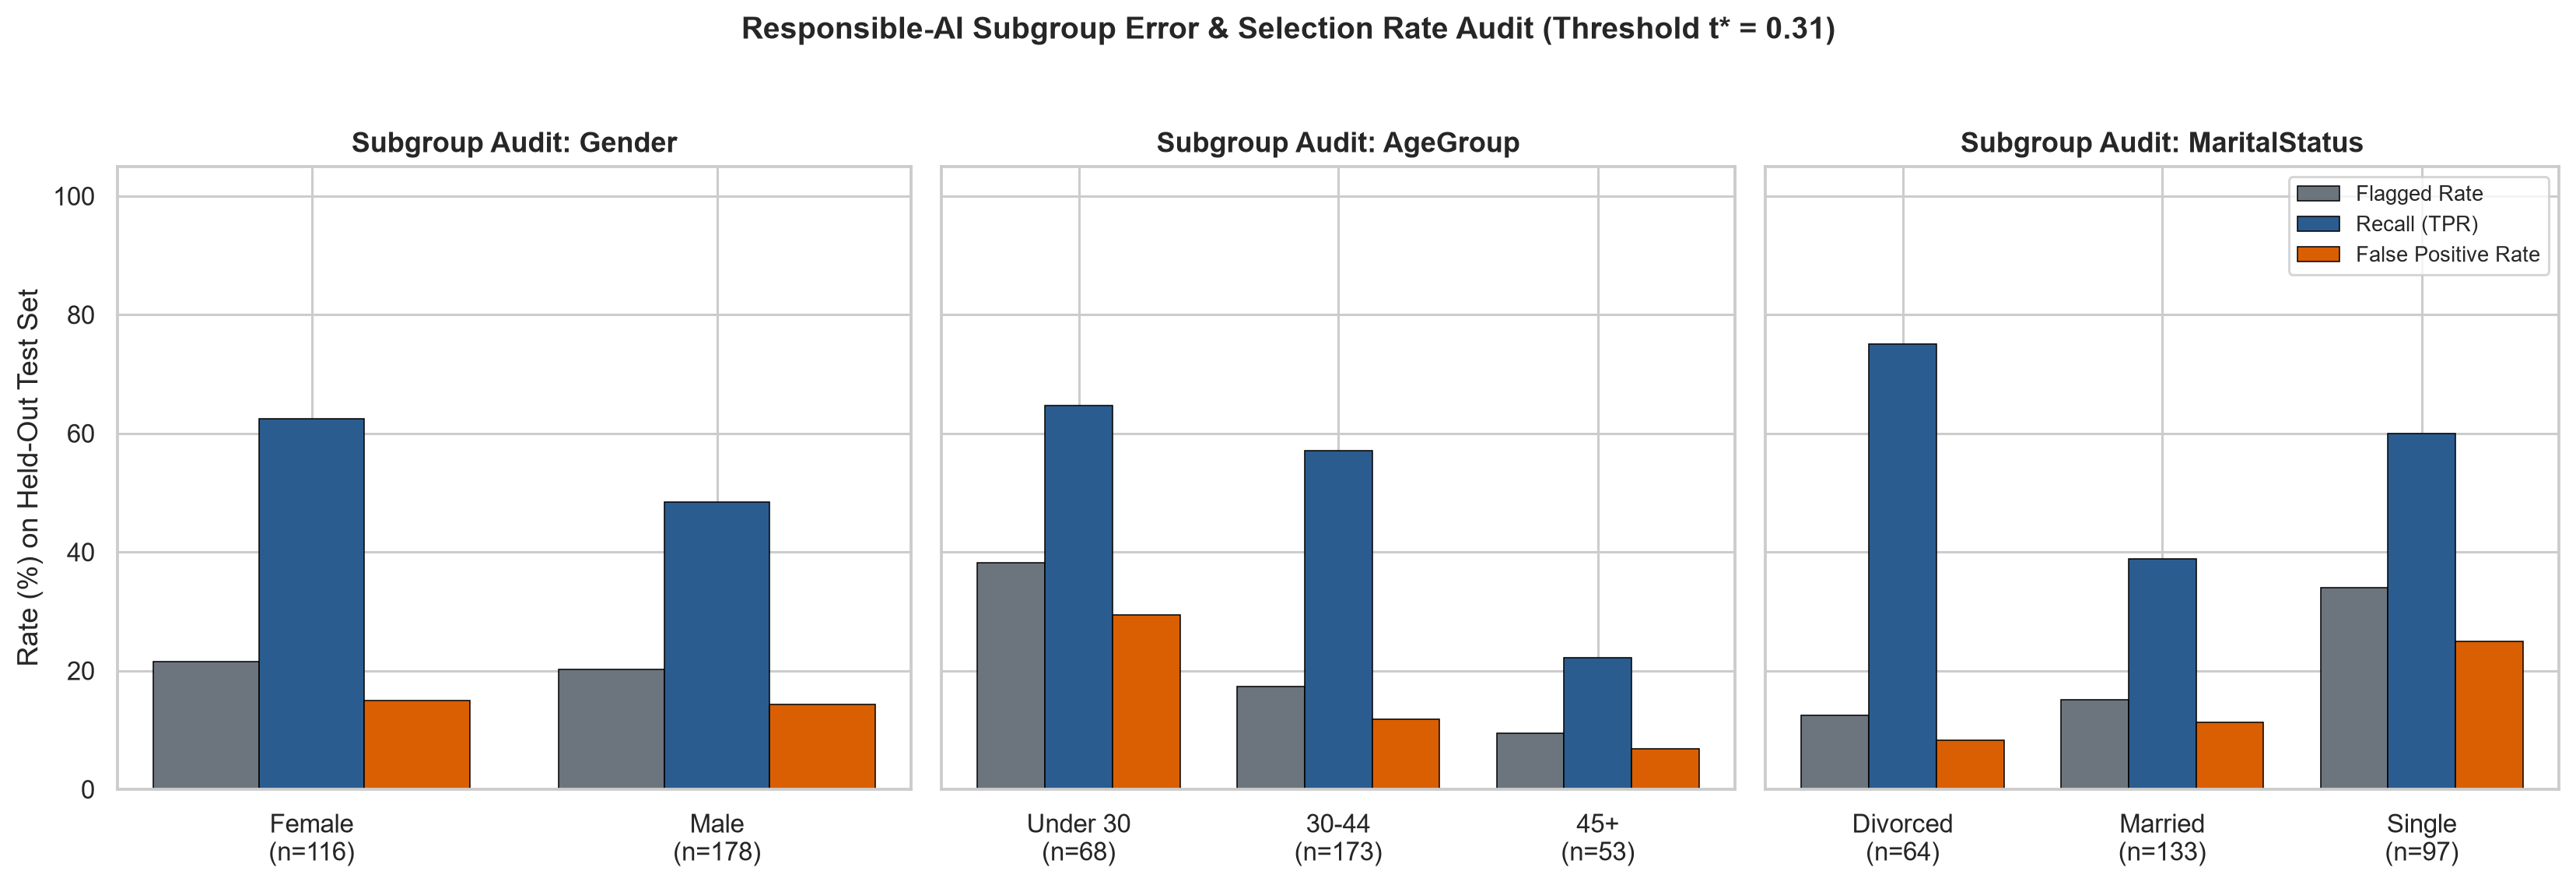

In [10]:
subgroup_df = pd.read_csv(cfg.metrics_dir / "subgroup_audit.csv")
ablation_res = json.loads((cfg.metrics_dir / "fairness_ablation.json").read_text(encoding="utf-8"))

display(subgroup_df)
print("\nSensitive-Attribute Ablation Check (L1 Logistic Regression):")
print(json.dumps(ablation_res, indent=2))

display(Image(filename=str(cfg.figures_dir / "fig11_subgroup_audit.png"), width=920))